## GraphRAG 응용 - Tool-based Agentic RAG 구조

> 프로젝트가 끝나면 설계서·보고서·이슈 목록이 **저장만 되고 재활용되지 않아**, 비슷한 프로젝트에서 같은 시행착오가 반복됩니다.
> 이 노트북은 산출물에서 **기술 지식(적용 기술, 문제 해결 사례, 교훈)** 을 뽑아 **지식 카드**로 만들고, Neo4j 그래프에 쌓아 **에이전트가 검색·질의응답·추천**하게 만듭니다.

#### 사용자 질문 → LLM 판단 → 도구 호출 → 검색 결과 확인 → 필요하면 추가 도구 호출 → 최종 답변

| 주요 기능 | 이 노트북에서 |
|---|---|
| 산출물 파싱 | **Word(설계서·결과보고서) + Excel(이슈 목록)** 2종으로 한정 (PDF·PPT 확장 방법은 3장 참고) |
| 지식 추출 | 이슈 목록(Excel)은 **코드로 바로** 변환, 보고서(Word)는 **LLM이 정해진 칸 채우기** |
| 지식 카드 + 태깅 | 표준 카드 형식(유형·제목·요약·문제·해결·기술·태그) + 사람이 확인할 엑셀 저장 |
| 검색·Q&A (출처 제시) | 벡터 검색 + 그래프 조회 도구, 답변마다 `(출처: 프로젝트 / 파일)` |
| 유사 프로젝트·지식 추천 | 신규 프로젝트 설명 → 기술 추출 → **기술을 공유하는 과거 프로젝트와 카드** 추천 |
| 웹 데모 | Gradio 채팅 화면 |

#### 설계 원칙: "심플한 GraphRAG"
| 어려운 방식 | 이 노트북의 방식 |
|---|---|
| LLM이 문서에서 그래프를 **자유롭게 추출** | LLM은 **정해진 칸(지식 카드)만 채우고**, 그래프는 코드(`MERGE`)가 만든다 |
| LLM이 Cypher를 **직접 생성** (Text2Cypher) | 개발자가 검증한 **고정 Cypher를 도구(@tool)로** 제공 |
| 벡터·그래프를 한 쿼리로 복잡하게 결합 | **문서 검색 도구**와 **그래프 도구**를 에이전트가 골라 쓴다 |

> **한눈에 보기**
> - 프로젝트 산출물(설계서·결과보고서 Word, 이슈목록 Excel)에서 **지식 카드**(적용기술·문제해결·교훈)를 뽑아 Neo4j에 쌓고, 도구 5개 에이전트로 검색·출처 있는 Q&A·신규 프로젝트 추천
> - "심플한 GraphRAG": LLM은 정해진 칸만 채우고 그래프는 코드(`MERGE`)가, Cypher는 검증된 고정 쿼리. Excel 이슈는 LLM 없이 코드로, 기술명은 사전으로 정규화
> - 실행 결과: 설계서에서 LLM이 지어낸 문제해결 카드와 빈 교훈 카드가 나왔고, 에이전트가 그 카드를 출처까지 붙여 답했다 → 사람 확인 단계가 필요한 이유
> - 정리 문서: [지식자산화GraphRAG에이전트.md](지식자산화GraphRAG에이전트.md) · 강의 슬라이드 이미지 포함, 📝 정리 셀은 직접 정리

### 전체 흐름
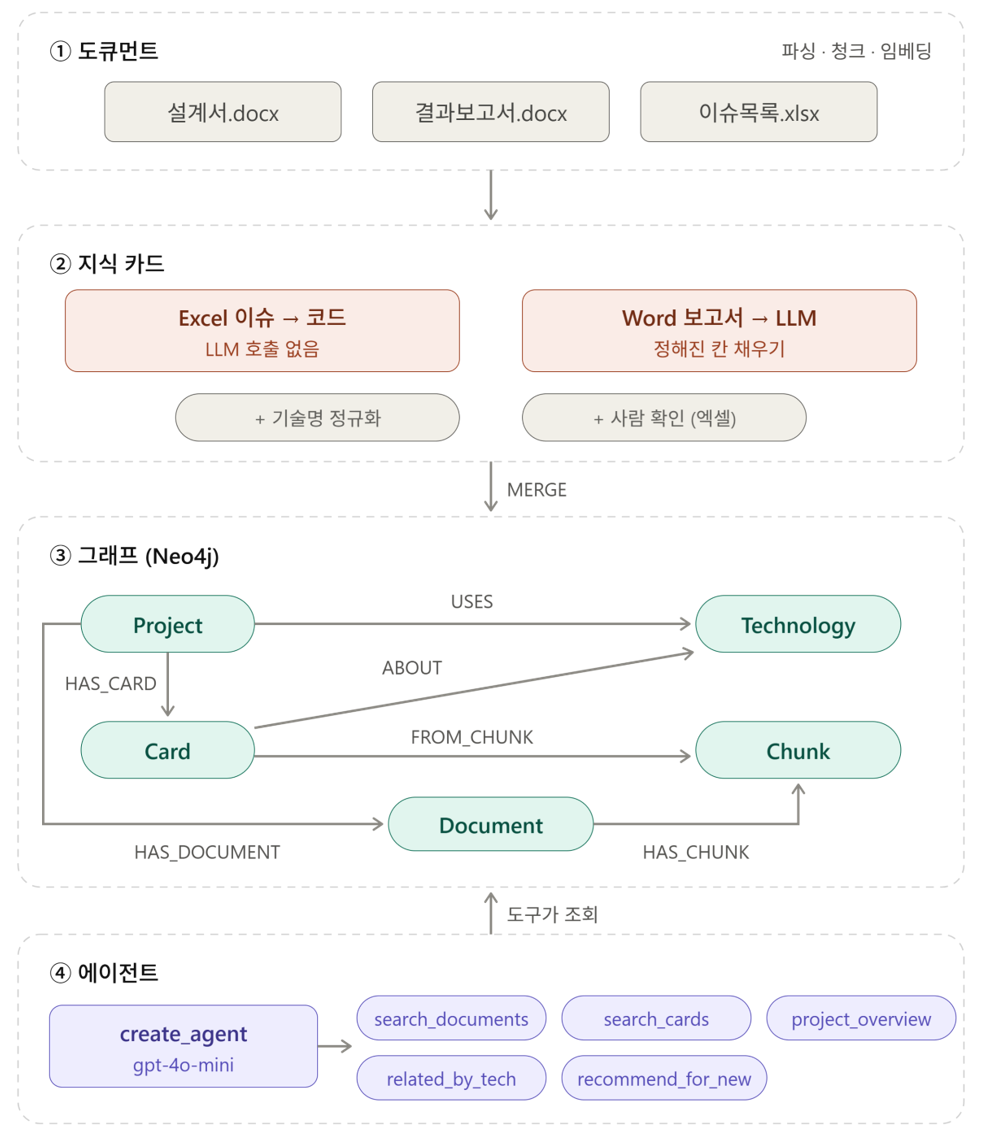

- **Chunk와 Card의 차이** \
Chunk 15개는 원문과 임베딩을 저장하고, Card 29개는 원문에서 추출한 기술·문제해결·교훈 등의 구조화된 지식을 저장합니다.

- **LLM의 검색 도구 선택** \
LLM이 질문을 분석해 VectorRAG 또는 GraphRAG 도구를 선택합니다. 필요하면 여러 도구를 연속으로 호출할 수도 있습니다.

- **표준 지식카드의 필요성** \
문서마다 표현이 다른 기술 경험을 일정한 구조로 정리하면, 기술별 검색과 프로젝트 간 관계 분석, 과거 경험을 활용한 신규 프로젝트 추천이 쉬워집니다. 표준 지식카드에는 카드 유형, 기술, 문제 상황, 해결 방법, 교훈, 원문 출처 등을 포함하는 것이 좋습니다.

#### AI 에이전트가 VectorRAG와 GraphRAG 검색 도구를 선택하거나 조합하는 구조

```
@tool
def search_documents(...):
    # VectorRAG: 유사 문서 청크 검색

@tool
def search_knowledge_cards(...):
    # GraphRAG: 지식 카드 검색

@tool
def get_project_overview(...):
    # GraphRAG: 프로젝트 정보 조회

@tool
def find_related_by_technology(...):
    # GraphRAG: 기술 관계 탐색

@tool
def recommend_for_new_project(...):
    # LLM 기술 추출 + 그래프 기반 추천
```

```
agent = create_agent(
    model=llm,
    tools=tools,
    checkpointer=checkpointer,
    system_prompt=system_prompt
)
```

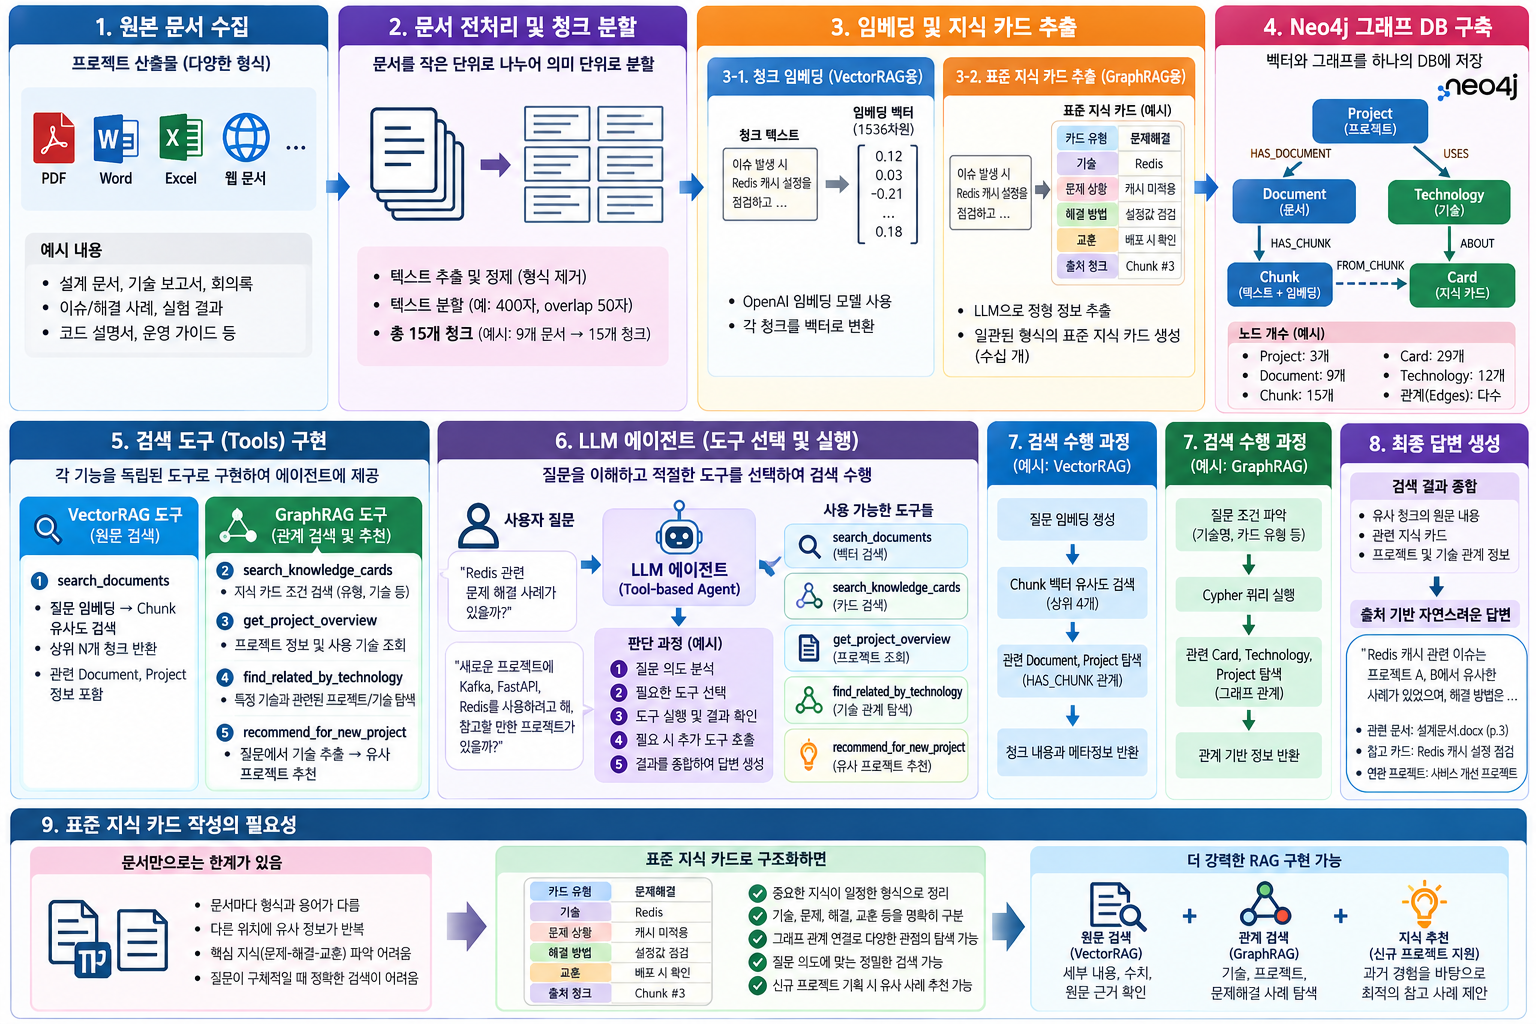

---
### 0. 환경 준비
**Python 3.12**, 2026년 11월 기준 최신 버전으로 고정했습니다. Neo4j는 **Desktop / Docker / AuraDB Free** 어느 것이든 됩니다 (5.x 이상, 벡터 인덱스 사용).

In [1]:
'''
%pip install -q \
    langchain==1.4.7 \
    langchain-core==1.7.3 \
    langchain-openai==1.7.3 \
    langchain-text-splitters==1.1.3 \
    neo4j==6.4.1 \
    python-docx==1.2.0 \
    openpyxl==3.1.5 \
    pandas==3.1.0 \
    gradio==6.31.0 \
    python-dotenv==1.2.4
'''

'\n%pip install -q     langchain==1.4.7     langchain-core==1.7.3     langchain-openai==1.7.3     langchain-text-splitters==1.1.3     neo4j==6.4.1     python-docx==1.2.0     openpyxl==3.1.5     pandas==3.1.0     gradio==6.31.0     python-dotenv==1.2.4\n'

In [2]:
%pip install -q python-docx==1.2.0 openpyxl==3.1.5 gradio==6.31.0 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


환경변수를 설정하고 VS Code를 재시작합니다. (AuraDB는 `NEO4J_URI`가 `neo4j+s://xxxx.databases.neo4j.io` 형식)
```
setx OPENAI_API_KEY "sk-..."
setx NEO4J_URI "neo4j://localhost:7687"
setx NEO4J_USERNAME "neo4j"
setx NEO4J_PASSWORD "비밀번호"
```

In [3]:
import os
from neo4j import GraphDatabase
from langchain_openai import ChatOpenAI, OpenAIEmbeddings      # [LangChain]

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)
embedder = OpenAIEmbeddings(model="text-embedding-3-small")    # 1536 차원

driver = GraphDatabase.driver(
    os.getenv("NEO4J_URI", "neo4j://localhost:7687"),
    auth=(os.getenv("NEO4J_USERNAME", "neo4j"), os.getenv("NEO4J_PASSWORD", "password")),
)
driver.verify_connectivity()
print("✅ OpenAI 키:", "있음" if os.getenv("OPENAI_API_KEY") else "❌ 없음")
print("✅ Neo4j 연결 성공")


def run(query: str, **params) -> list[dict]:
    # Cypher 실행 → 딕셔너리 리스트로 돌려주는 공통 함수
    records, _, _ = driver.execute_query(query, params, database_="neo4j")
    return [r.data() for r in records]

✅ OpenAI 키: 있음
✅ Neo4j 연결 성공


---
### 1. 가상 프로젝트 산출물 만들기
실제로는 회사의 파일 서버에 있는 산출물을 쓰지만, 실습용으로 **3개 프로젝트 × 3종 산출물(9개 파일)** 을 만듭니다.

| ID | 프로젝트 | 분야 | 주요 기술 |
|---|---|---|---|
| P001 | 스마트팩토리 설비 모니터링 | 제조 | Kafka, InfluxDB, Grafana, MQTT, FastAPI |
| P002 | 사내 문서 RAG 챗봇 | 사무 | LangChain, pgvector, PostgreSQL, BM25, Redis, FastAPI |
| P003 | 쇼핑몰 상품 추천 시스템 | 커머스 | Kafka, Spark, Redis, FastAPI |

<br>

> 💡 **Kafka, Redis, FastAPI**가 여러 프로젝트에 겹치도록 만들었습니다. 이 겹침이 그래프에서 "비슷한 프로젝트"를 찾는 연결 고리가 됩니다.

프로젝트 기본 정보(이름·분야·연도·요약)는 PMS(프로젝트 관리 시스템)에 이미 있는 **구조화 데이터**라고 가정하고 딕셔너리로 둡니다.

In [4]:
from pathlib import Path
from docx import Document as DocxDocument
import pandas as pd

DATA_DIR = Path("project_outputs")

# 프로젝트 기본 정보 (PMS 의 구조화 데이터라고 가정)
PROJECTS = {
    "P001": {"name": "스마트팩토리 설비 모니터링", "domain": "제조", "year": 2024,
             "summary": "공장 설비 120대의 센서 데이터를 실시간 수집해 이상 징후를 감지하는 모니터링 시스템"},
    "P002": {"name": "사내 문서 RAG 챗봇", "domain": "사무", "year": 2025,
             "summary": "사내 규정·매뉴얼 3,000건을 검색해 답변하는 RAG 기반 질의응답 챗봇"},
    "P003": {"name": "쇼핑몰 상품 추천 시스템", "domain": "커머스", "year": 2025,
             "summary": "회원 50만 명 쇼핑몰의 클릭·구매 이력 기반 개인화 상품 추천 시스템"},
}

# Word 산출물: {프로젝트: {파일명: [(소제목, 본문), ...]}}
WORD_DOCS = {
    "P001": {
        "설계서.docx": [
            ("개요", "공장 내 설비 120대의 진동·온도 센서 데이터를 실시간으로 수집하여 이상 징후를 조기에 감지한다."),
            ("아키텍처", "센서 데이터는 MQTT 브로커를 거쳐 Kafka 토픽으로 전달되고, Python 수집기가 InfluxDB에 시계열로 저장한다. "
                       "대시보드는 Grafana로 구성하고, 외부 시스템 연동 API는 FastAPI로 제공한다."),
            ("기술 선정 이유", "InfluxDB는 시계열 데이터 압축과 집계 성능이 좋아 선택했다. Kafka는 센서 증가에 대비한 확장성 때문에 도입했다."),
            ("비기능 요구사항", "데이터 수집 지연은 2초 이내, 데이터 보관 기간은 1년으로 한다."),
        ],
        "결과보고서.docx": [
            ("수행 결과", "설비 120대 연동을 완료했으며, 이상 감지 알림까지 평균 1.2초가 걸린다."),
            ("주요 문제 해결", "운영 2주 차에 센서 데이터 수집 지연이 최대 30초까지 발생했다. 원인은 Kafka 토픽 파티션이 1개라 수집기 1대만 처리했기 때문이다. "
                           "파티션을 6개로 늘리고 수집기를 컨슈머 그룹으로 3대까지 확장하여 지연을 1초 이내로 줄였다."),
            ("교훈", "부하 테스트를 실제 센서 수(120대) 규모로 하지 않아 운영 단계에서야 성능 문제를 발견했다. 초기부터 실데이터 규모의 부하 테스트를 계획해야 한다. "
                    "또한 InfluxDB 보관 정책(retention)을 설계 단계에서 정하지 않아 디스크 사용량이 급증했다."),
        ],
    },
    "P002": {
        "설계서.docx": [
            ("개요", "사내 규정과 업무 매뉴얼 약 3,000건을 대상으로 직원 질문에 답하는 챗봇을 구축한다."),
            ("아키텍처", "문서를 LangChain으로 분할하고 OpenAI 임베딩으로 벡터화하여 PostgreSQL의 pgvector에 저장한다. "
                       "질문은 FastAPI 서버가 받아 관련 문서를 검색한 뒤 LLM이 답변을 생성한다."),
            ("기술 선정 이유", "사내에 PostgreSQL 운영 경험이 많아 별도 벡터 DB 대신 pgvector를 선택했다."),
        ],
        "결과보고서.docx": [
            ("수행 결과", "평가 질문 200개 기준 답변 정확도 82%를 달성했다."),
            ("주요 문제 해결", "사내 약어와 'HR-204' 같은 규정 코드를 묻는 질문의 검색 정확도가 낮았다. 벡터 검색은 정확한 문자열 매칭에 약하기 때문이다. "
                           "BM25 키워드 검색과 벡터 검색을 결합한 하이브리드 검색을 적용해 정확도를 64%에서 82%로 높였다."),
            ("교훈", "평가 질문셋을 프로젝트 후반에 만들어 개선 효과를 수치로 확인하기 어려웠다. 프로젝트 초기에 평가셋부터 만들어야 한다."),
        ],
    },
    "P003": {
        "설계서.docx": [
            ("개요", "회원 50만 명 규모 쇼핑몰에 개인화 상품 추천 기능을 제공한다."),
            ("아키텍처", "클릭·구매 이벤트를 Kafka로 수집하고, Spark로 매일 밤 협업 필터링 모델을 학습한다. "
                       "추천 결과는 Redis에 저장하고 FastAPI 추천 API로 제공한다."),
            ("기술 선정 이유", "대규모 배치 학습에는 Spark를, 밀리초 단위 응답에는 Redis를 선택했다."),
        ],
        "결과보고서.docx": [
            ("수행 결과", "추천 영역 클릭률이 2.1%에서 3.4%로 올랐다."),
            ("주요 문제 해결", "추천 API 응답이 평균 900ms로 느렸다. 요청 시점에 계산하던 방식을 바꿔 사전 계산 결과를 Redis에 저장하여 평균 40ms로 줄였다. "
                           "신규 회원은 구매 이력이 없어 추천이 비는 콜드스타트 문제가 있었고, 인기 상품과 가입 시 선택한 관심 카테고리 기반 추천으로 대체했다."),
            ("교훈", "오프라인 평가 지표가 높았던 모델이 실제 클릭률은 낮았다. 배포 전 A/B 테스트를 반드시 거쳐야 한다. "
                    "Kafka 이벤트 유실을 늦게 발견했으므로 수집 단계 모니터링이 필요하다."),
        ],
    },
}

# Excel 산출물: 이슈 목록
ISSUES = {
    "P001": [
        ["I-01", "수집 지연", "센서 데이터가 최대 30초 늦게 저장됨", "Kafka 파티션 1개로 병렬 처리 불가", "파티션 6개로 증설, 컨슈머 3대 확장", "Kafka", "완료"],
        ["I-02", "디스크 사용량 급증", "한 달 만에 디스크 90% 사용", "InfluxDB retention 미설정", "원본 30일 보관 + 1시간 단위 다운샘플링", "InfluxDB", "완료"],
        ["I-03", "대시보드 로딩 지연", "1년치 그래프 조회 시 20초 이상 소요", "원본 데이터를 그대로 조회", "다운샘플링 데이터로 조회하도록 패널 수정", "Grafana, InfluxDB", "완료"],
    ],
    "P002": [
        ["I-01", "코드 검색 실패", "'HR-204' 질문에 엉뚱한 문서를 답변", "벡터 검색은 코드 같은 정확한 문자열에 약함", "BM25 + 벡터 하이브리드 검색 적용", "pgvector, BM25", "완료"],
        ["I-02", "표 내용 누락", "PDF 표 안의 수치를 답변하지 못함", "텍스트 추출 시 표 구조가 깨짐", "표를 별도로 추출해 마크다운 표로 저장", "LangChain", "완료"],
        ["I-03", "응답 지연", "평균 응답 시간 8초", "같은 질문도 매번 LLM 호출", "자주 묻는 질문의 답변을 Redis에 캐시", "Redis, FastAPI", "완료"],
    ],
    "P003": [
        ["I-01", "신규 회원 추천 없음", "가입 직후 추천 영역이 비어 있음", "구매 이력이 없는 콜드스타트", "인기 상품 + 관심 카테고리 기반 대체 추천", "Spark", "완료"],
        ["I-02", "추천 API 지연", "평균 응답 900ms", "요청마다 모델 계산", "사전 계산 결과를 Redis에 저장", "Redis, FastAPI", "완료"],
        ["I-03", "클릭 이벤트 유실", "하루 약 3% 이벤트 누락", "Kafka 프로듀서 acks=1 설정", "acks=all 및 재시도 설정", "Kafka", "완료"],
    ],
}
ISSUE_COLUMNS = ["ID", "제목", "현상", "원인", "해결", "관련기술", "상태"]

# 파일로 저장
for pid, docs in WORD_DOCS.items():
    folder = DATA_DIR / pid
    folder.mkdir(parents=True, exist_ok=True)
    for fname, sections in docs.items():
        doc = DocxDocument()
        doc.add_heading(f"{PROJECTS[pid]['name']} {fname.replace('.docx', '')}", level=0)
        for title, body in sections:
            doc.add_heading(title, level=1)
            doc.add_paragraph(body)
        doc.save(folder / fname)
    pd.DataFrame(ISSUES[pid], columns=ISSUE_COLUMNS).to_excel(folder / "이슈목록.xlsx", index=False)

for f in sorted(DATA_DIR.rglob("*.*")):
    print("📄", f)

📄 project_outputs\P001\결과보고서.docx
📄 project_outputs\P001\설계서.docx
📄 project_outputs\P001\이슈목록.xlsx
📄 project_outputs\P002\결과보고서.docx
📄 project_outputs\P002\설계서.docx
📄 project_outputs\P002\이슈목록.xlsx
📄 project_outputs\P003\결과보고서.docx
📄 project_outputs\P003\설계서.docx
📄 project_outputs\P003\이슈목록.xlsx


---
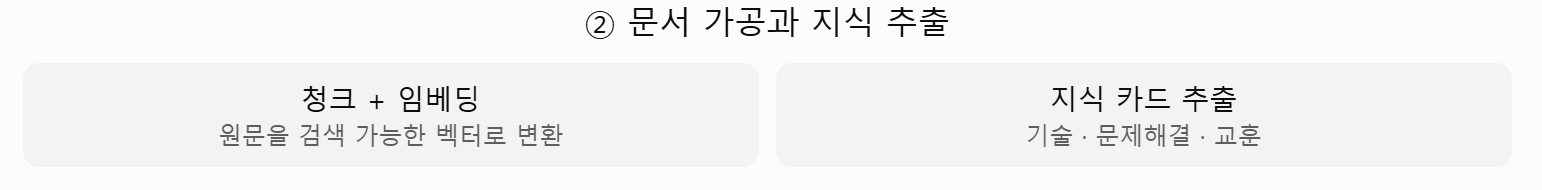

### 2. 도큐먼트: 파싱 → 청크 → 임베딩
형식마다 **파서 함수**를 하나씩 두고, 확장자로 골라 씁니다. 결과는 모두 같은 모양 `{"project_id", "file", "doc_type", "text"}`로 통일합니다.

| 형식 | 파싱 방법 | 청크 방식 |
|---|---|---|
| Word | `python-docx`로 문단 읽기, 제목은 `## `로 표시 | 글자 수 기준 분할 (`RecursiveCharacterTextSplitter`) |
| Excel | `pandas`로 행 읽기 | **이슈 1건 = 청크 1개** (이미 잘 나뉘어 있음) |

In [5]:
from langchain_text_splitters import RecursiveCharacterTextSplitter                 # [LangChain]


def parse_docx(path: Path) -> str:
    lines = []
    for p in DocxDocument(path).paragraphs:
        if not p.text.strip():
            continue
        is_heading = p.style.name.startswith(("Heading", "Title"))
        lines.append(f"## {p.text}" if is_heading else p.text)
    return "\n".join(lines)


def parse_xlsx(path: Path) -> list[dict]:
    return pd.read_excel(path).fillna("").to_dict("records")       # 행 = 딕셔너리


def issue_to_text(row: dict) -> str:
    return (f"[이슈 {row['ID']}] {row['제목']}\n현상: {row['현상']}\n원인: {row['원인']}\n"
            f"해결: {row['해결']}\n관련기술: {row['관련기술']}")


splitter = RecursiveCharacterTextSplitter(chunk_size=400, chunk_overlap=50, separators=["\n## ", "\n", ". ", " "])

chunks = []          # 모든 청크: {chunk_id, doc_id, project_id, file, doc_type, text, (issue)}
for path in sorted(DATA_DIR.rglob("*.*")):
    pid, fname = path.parent.name, path.name
    doc_id = f"{pid}/{fname}"
    if path.suffix == ".docx":
        doc_type = fname.replace(".docx", "")
        for i, text in enumerate(splitter.split_text(parse_docx(path))):
            chunks.append({"chunk_id": f"{doc_id}#{i}", "doc_id": doc_id, "project_id": pid,
                           "file": fname, "doc_type": doc_type, "text": text})
    elif path.suffix == ".xlsx":
        for i, row in enumerate(parse_xlsx(path)):
            chunks.append({"chunk_id": f"{doc_id}#{i}", "doc_id": doc_id, "project_id": pid,
                           "file": fname, "doc_type": "이슈목록", "text": issue_to_text(row), "issue": row})

print(f"청크 {len(chunks)}개")
print("-" * 60)
print(chunks[0]["chunk_id"], "\n", chunks[0]["text"])

청크 15개
------------------------------------------------------------
P001/결과보고서.docx#0 
 ## 스마트팩토리 설비 모니터링 결과보고서
## 수행 결과
설비 120대 연동을 완료했으며, 이상 감지 알림까지 평균 1.2초가 걸린다.
## 주요 문제 해결
운영 2주 차에 센서 데이터 수집 지연이 최대 30초까지 발생했다. 원인은 Kafka 토픽 파티션이 1개라 수집기 1대만 처리했기 때문이다. 파티션을 6개로 늘리고 수집기를 컨슈머 그룹으로 3대까지 확장하여 지연을 1초 이내로 줄였다.
## 교훈
부하 테스트를 실제 센서 수(120대) 규모로 하지 않아 운영 단계에서야 성능 문제를 발견했다. 초기부터 실데이터 규모의 부하 테스트를 계획해야 한다. 또한 InfluxDB 보관 정책(retention)을 설계 단계에서 정하지 않아 디스크 사용량이 급증했다.


> 💡 **PDF·PPT로 확장하려면** 파서 함수만 추가하면 됩니다. 뒤의 과정(청크·카드·그래프)은 그대로입니다.
> ```python
> from pypdf import PdfReader            # pip install pypdf
> def parse_pdf(path):  return "\n".join(page.extract_text() for page in PdfReader(path).pages)
>
> from pptx import Presentation          # pip install python-pptx
> def parse_pptx(path): return "\n".join(sh.text for s in Presentation(path).slides for sh in s.shapes if sh.has_text_frame)
> ```

In [6]:
# 청크 임베딩 (한 번에 묶어서 요청)
vectors = embedder.embed_documents([c["text"] for c in chunks])
for c, v in zip(chunks, vectors):
    c["embedding"] = v
print(f"임베딩 완료: {len(vectors)}개 × {len(vectors[0])}차원")

임베딩 완료: 15개 × 1536차원


---
### 3. 지식 카드 추출
**지식 카드** = 재활용할 수 있는 기술 지식 1건을 정해진 형식으로 정리한 것입니다.

| 칸 | 내용 | 예 |
|---|---|---|
| `card_type` | **적용기술 / 문제해결 / 교훈** 중 하나 | 문제해결 |
| `title` | 한 줄 제목 | Kafka 파티션 부족으로 인한 수집 지연 |
| `summary` | 두세 문장 요약 | … |
| `problem` / `solution` | 문제와 해결 (문제해결 카드만) | 30초 지연 / 파티션 6개 증설 |
| `technologies` | 관련 기술 (**정규화된 이름**) | `["Kafka"]` |
| `tags` | 검색용 태그 | `["성능", "확장성"]` |

<br>

| 원천 | 추출 방법 | 이유 |
|---|---|---|
| **이슈 목록 (Excel)** | **코드로 바로** 카드 변환 | 이미 칸이 나뉜 구조화 데이터 → LLM이 필요 없음 (정확·무료) |
| **설계서·결과보고서 (Word)** | **LLM이 카드 칸 채우기** (`with_structured_output`) | 자유 문장이라 LLM이 필요. 단, **형식은 코드가 고정** |

In [7]:
import hashlib
from typing import Literal
from pydantic import BaseModel, Field

# ── 기술명 정규화: 같은 기술이 다른 이름으로 들어오는 것을 막는다 (엔티티 해소의 가장 쉬운 방법) ──
KNOWN_TECH = ["Kafka", "InfluxDB", "Grafana", "MQTT", "Python", "FastAPI", "LangChain", "pgvector",
              "PostgreSQL", "OpenAI", "BM25", "Redis", "Spark", "Docker", "Kubernetes", "Elasticsearch"]
ALIASES = {"카프카": "Kafka", "레디스": "Redis", "스파크": "Spark", "postgres": "PostgreSQL",
           "그라파나": "Grafana", "인플럭스db": "InfluxDB", "랭체인": "LangChain", "k8s": "Kubernetes"}
_LOOKUP = {t.lower(): t for t in KNOWN_TECH} | ALIASES

def normalize_tech(name: str) -> str:
    key = name.strip().lower().replace(" ", "").replace("-", "")
    return _LOOKUP.get(key, name.strip())

def normalize_techs(names) -> list[str]:
    return sorted({normalize_tech(n) for n in names if n and n.strip()})

def make_card_id(project_id: str, title: str) -> str:
    return "C-" + hashlib.md5(f"{project_id}|{title}".encode()).hexdigest()[:8]

print(normalize_techs(["kafka", "레디스", "Fast API", "fastapi", "Spark"]))

['FastAPI', 'Kafka', 'Redis', 'Spark']


In [8]:
# ── ① Excel 이슈 → 카드 (LLM 없이 코드로) ──────────────────
cards = []
for c in chunks:
    if c["doc_type"] != "이슈목록":
        continue
    row = c["issue"]
    cards.append({
        "card_id": make_card_id(c["project_id"], row["제목"]),
        "project_id": c["project_id"], "chunk_id": c["chunk_id"],
        "card_type": "문제해결",
        "title": row["제목"],
        "summary": f"{row['현상']} — 원인: {row['원인']} → 해결: {row['해결']}",
        "problem": f"{row['현상']} (원인: {row['원인']})",
        "solution": row["해결"],
        "technologies": normalize_techs(str(row["관련기술"]).split(",")),
        "tags": ["이슈"],
    })
print(f"이슈 → 카드 {len(cards)}개 (LLM 호출 0회)")

이슈 → 카드 9개 (LLM 호출 0회)


**📝 정리** — Excel 이슈 9건 → 카드 9개, LLM 호출 0회. 이미 칸이 나뉜 데이터는 코드로 옮기는 것이 정확하고 무료다.

In [9]:
# ── ② Word 보고서 → 카드 (LLM 이 '정해진 칸'만 채운다) ────────
class Card(BaseModel):
    card_type: Literal["적용기술", "문제해결", "교훈"]
    title: str = Field(description="30자 이내 한 줄 제목")
    summary: str = Field(description="두세 문장 요약. 수치가 있으면 포함")
    problem: str | None = Field(default=None, description="문제해결 카드일 때만: 무엇이 문제였나 (원인 포함)")
    solution: str | None = Field(default=None, description="문제해결 카드일 때만: 어떻게 해결했나")
    technologies: list[str] = Field(default_factory=list, description="관련 기술 이름 (예: Kafka, Redis)")
    tags: list[str] = Field(default_factory=list, description="검색용 태그 2~3개 (예: 성능, 확장성, 품질, 운영)")


class CardList(BaseModel):
    cards: list[Card] = Field(description="이 글에서 재활용할 가치가 있는 지식. 없으면 빈 리스트")


card_extractor = llm.with_structured_output(CardList)

EXTRACT_PROMPT = f'''너는 프로젝트 산출물에서 재활용할 기술 지식을 뽑는 지식 관리자다.
아래 글에서 지식 카드를 만들어라.
- 적용기술: 어떤 기술을 왜 선택했는지
- 문제해결: 실제로 겪은 문제와 해결 방법 (problem, solution 필수)
- 교훈: 다음 프로젝트에서 반드시 기억할 점
기술 이름은 가능하면 이 목록의 표기를 그대로 써라: {", ".join(KNOWN_TECH)}
글에 없는 내용은 만들지 마라. 단순 개요나 수치 보고만 있으면 카드를 만들지 마라.'''

for c in chunks:
    if c["doc_type"] == "이슈목록":
        continue
    result = card_extractor.invoke([("system", EXTRACT_PROMPT),
                                    ("user", f"[{PROJECTS[c['project_id']]['name']} / {c['file']}]\n{c['text']}")])
    for card in result.cards:
        cards.append({
            "card_id": make_card_id(c["project_id"], card.title),
            "project_id": c["project_id"], "chunk_id": c["chunk_id"],
            **card.model_dump(exclude={"technologies"}),
            "technologies": normalize_techs(card.technologies),          # LLM 결과도 코드로 정규화
        })

print(f"전체 카드 {len(cards)}개")
pd.DataFrame(cards)["card_type"].value_counts()

전체 카드 29개


card_type
문제해결    15
적용기술     7
교훈       7
Name: count, dtype: int64

### 사람이 확인하기
LLM이 만든 카드는 **엑셀로 저장해서 사람이 확인**한 뒤 그래프에 넣는 것이 안전합니다. (틀린 기술명, 중복 카드, 지어낸 내용 확인)

In [10]:
review = pd.DataFrame(cards).drop(columns=["chunk_id"])
review["technologies"] = review["technologies"].apply(", ".join)
review["tags"] = review["tags"].apply(", ".join)
review.to_excel("knowledge_cards_review.xlsx", index=False)
print("📝 knowledge_cards_review.xlsx 저장 → 열어서 확인하세요")
review[["project_id", "card_type", "title", "technologies", "tags"]]

📝 knowledge_cards_review.xlsx 저장 → 열어서 확인하세요


,project_id,card_type,title,technologies,tags
0,P001,문제해결,수집 지연,Kafka,이슈
1,P001,문제해결,디스크 사용량 급증,InfluxDB,이슈
2,P001,문제해결,대시보드 로딩 지연,"Grafana, InfluxDB",이슈
3,P002,문제해결,코드 검색 실패,"BM25, pgvector",이슈
4,P002,문제해결,표 내용 누락,LangChain,이슈
5,P002,문제해결,응답 지연,"FastAPI, Redis",이슈
6,P003,문제해결,신규 회원 추천 없음,Spark,이슈
7,P003,문제해결,추천 API 지연,"FastAPI, Redis",이슈
8,P003,문제해결,클릭 이벤트 유실,Kafka,이슈
9,P001,적용기술,Kafka,Kafka,"성능, 데이터 수집, 모니터링"


**📝 정리** — 카드 29개 중 설계서에서 나온 #14 "데이터 수집 지연 문제"는 비기능 요구사항(2초 이내)을 문제로 바꾸고 해결책을 지어냈다. #28 교훈 카드는 요약이 "다음 프로젝트에서 기억해야 할 점."뿐이고, #15·#21은 기술 선정 이유를 일반론 교훈으로 부풀렸다. 설계서에는 문제·교훈 항목이 없었다. 이 엑셀에서 사람이 걸러야 한다.

---
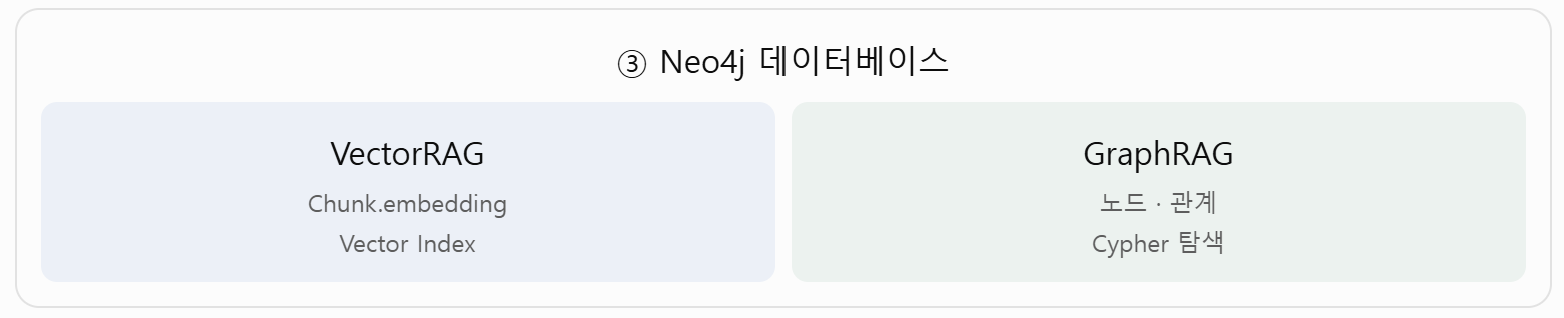

### 4. 그래프 구축 (Neo4j)
#### 스키마
| 노드 | 고유 키 | 주요 속성 |
|---|---|---|
| `Project` | `id` | name, domain, year, summary |
| `Document` | `id` | file, doc_type |
| `Chunk` | `id` | text, **embedding** (벡터 인덱스) |
| `Card` | `id` | card_type, title, summary, problem, solution, tags |
| `Technology` | `name` | |

<br>

| 관계 | 의미 |
|---|---|
| `(Project)-[:HAS_DOCUMENT]->(Document)-[:HAS_CHUNK]->(Chunk)` | 어휘 그래프 (원문 위치) |
| `(Project)-[:HAS_CARD]->(Card)` | 프로젝트의 지식 카드 |
| `(Card)-[:FROM_CHUNK]->(Chunk)` | **출처** (카드가 나온 원문) |
| `(Card)-[:ABOUT]->(Technology)` | 카드의 관련 기술 |
| `(Project)-[:USES]->(Technology)` | 프로젝트가 쓴 기술 (유사 프로젝트 찾기의 핵심) |

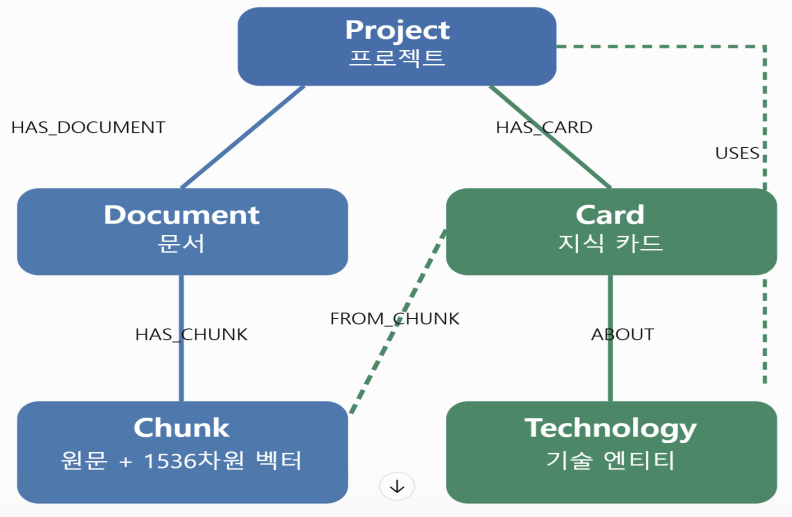

In [11]:
# 실습용: 기존 데이터 지우기 (⚠️ 다른 데이터가 있는 DB 에서는 실행하지 마세요)
run("MATCH (n) WHERE n:Project OR n:Document OR n:Chunk OR n:Card OR n:Technology DETACH DELETE n")

# 고유 제약 (중복 방지 + 자동 인덱스)
for label, key in [("Project", "id"), ("Document", "id"), ("Chunk", "id"), ("Card", "id"), ("Technology", "name")]:
    run(f"CREATE CONSTRAINT {label.lower()}_{key} IF NOT EXISTS FOR (n:{label}) REQUIRE n.{key} IS UNIQUE")

# 벡터 인덱스 (청크 임베딩 검색용)
run('''
CREATE VECTOR INDEX chunk_embedding IF NOT EXISTS
FOR (c:Chunk) ON c.embedding
OPTIONS {indexConfig: {`vector.dimensions`: 1536, `vector.similarity_function`: 'cosine'}}
''')
print("✅ 제약·인덱스 준비")

✅ 제약·인덱스 준비


In [12]:
# ① 프로젝트
run('''
UNWIND $rows AS row
MERGE (p:Project {id: row.id})
SET p.name = row.name, p.domain = row.domain, p.year = row.year, p.summary = row.summary
''', rows=[{"id": pid, **info} for pid, info in PROJECTS.items()])

# ② 문서 + 청크 (어휘 그래프)
run('''
UNWIND $rows AS row
MATCH (p:Project {id: row.project_id})
MERGE (d:Document {id: row.doc_id})
SET d.file = row.file, d.doc_type = row.doc_type
MERGE (p)-[:HAS_DOCUMENT]->(d)
MERGE (c:Chunk {id: row.chunk_id})
SET c.text = row.text, c.embedding = row.embedding
MERGE (d)-[:HAS_CHUNK]->(c)
''', rows=[{k: v for k, v in c.items() if k != "issue"} for c in chunks])

# ③ 지식 카드 + 기술 (지식 그래프)
run('''
UNWIND $rows AS row
MATCH (p:Project {id: row.project_id})
MATCH (ch:Chunk {id: row.chunk_id})
MERGE (c:Card {id: row.card_id})
SET c.card_type = row.card_type, c.title = row.title, c.summary = row.summary,
    c.problem = row.problem, c.solution = row.solution, c.tags = row.tags
MERGE (p)-[:HAS_CARD]->(c)
MERGE (c)-[:FROM_CHUNK]->(ch)
WITH p, c, row
UNWIND row.technologies AS tech
MERGE (t:Technology {name: tech})
MERGE (c)-[:ABOUT]->(t)
MERGE (p)-[:USES]->(t)
''', rows=cards)

run("CALL db.awaitIndexes(60)")      # 벡터 인덱스가 준비될 때까지 대기

for label in ["Project", "Document", "Chunk", "Card", "Technology"]:
    print(f"{label:11}: {run(f'MATCH (n:{label}) RETURN count(n) AS n')[0]['n']}개")

Project    : 3개
Document   : 9개
Chunk      : 15개
Card       : 29개
Technology : 12개


**📝 정리** — Project 3, Document 9, Chunk 15, Card 29, Technology 12.

Neo4j Browser에서 그래프를 눈으로 확인해 보세요.
```cypher
MATCH (p:Project)-[:USES]->(t:Technology) RETURN p, t                       // 프로젝트-기술 지도
MATCH (p:Project)-[:HAS_CARD]->(c:Card)-[:ABOUT]->(t:Technology {name:'Kafka'}) RETURN p, c, t   // Kafka 지식
```

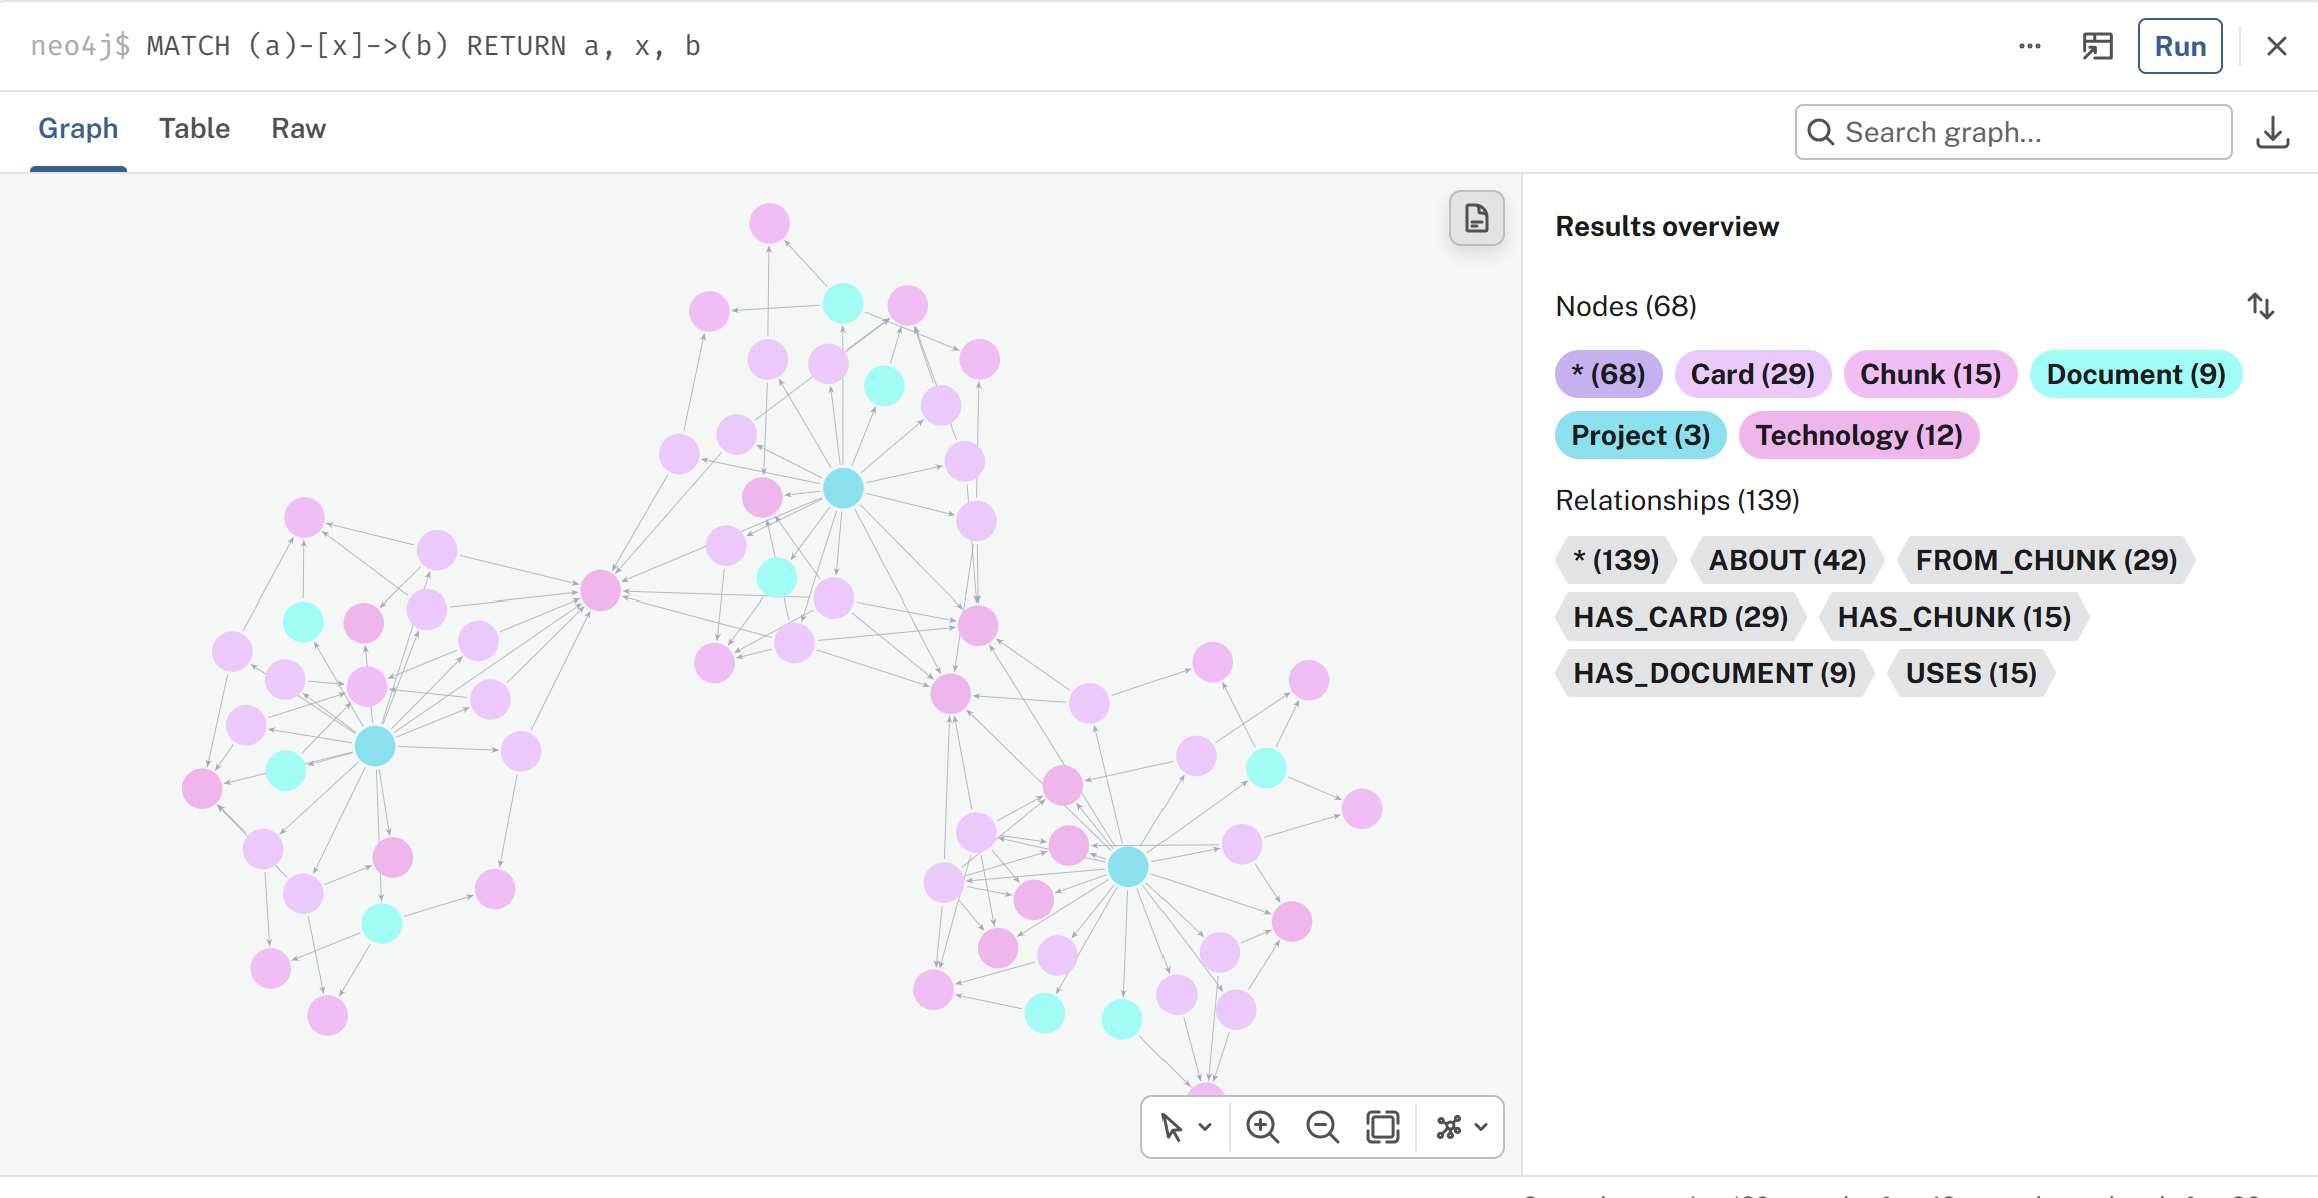

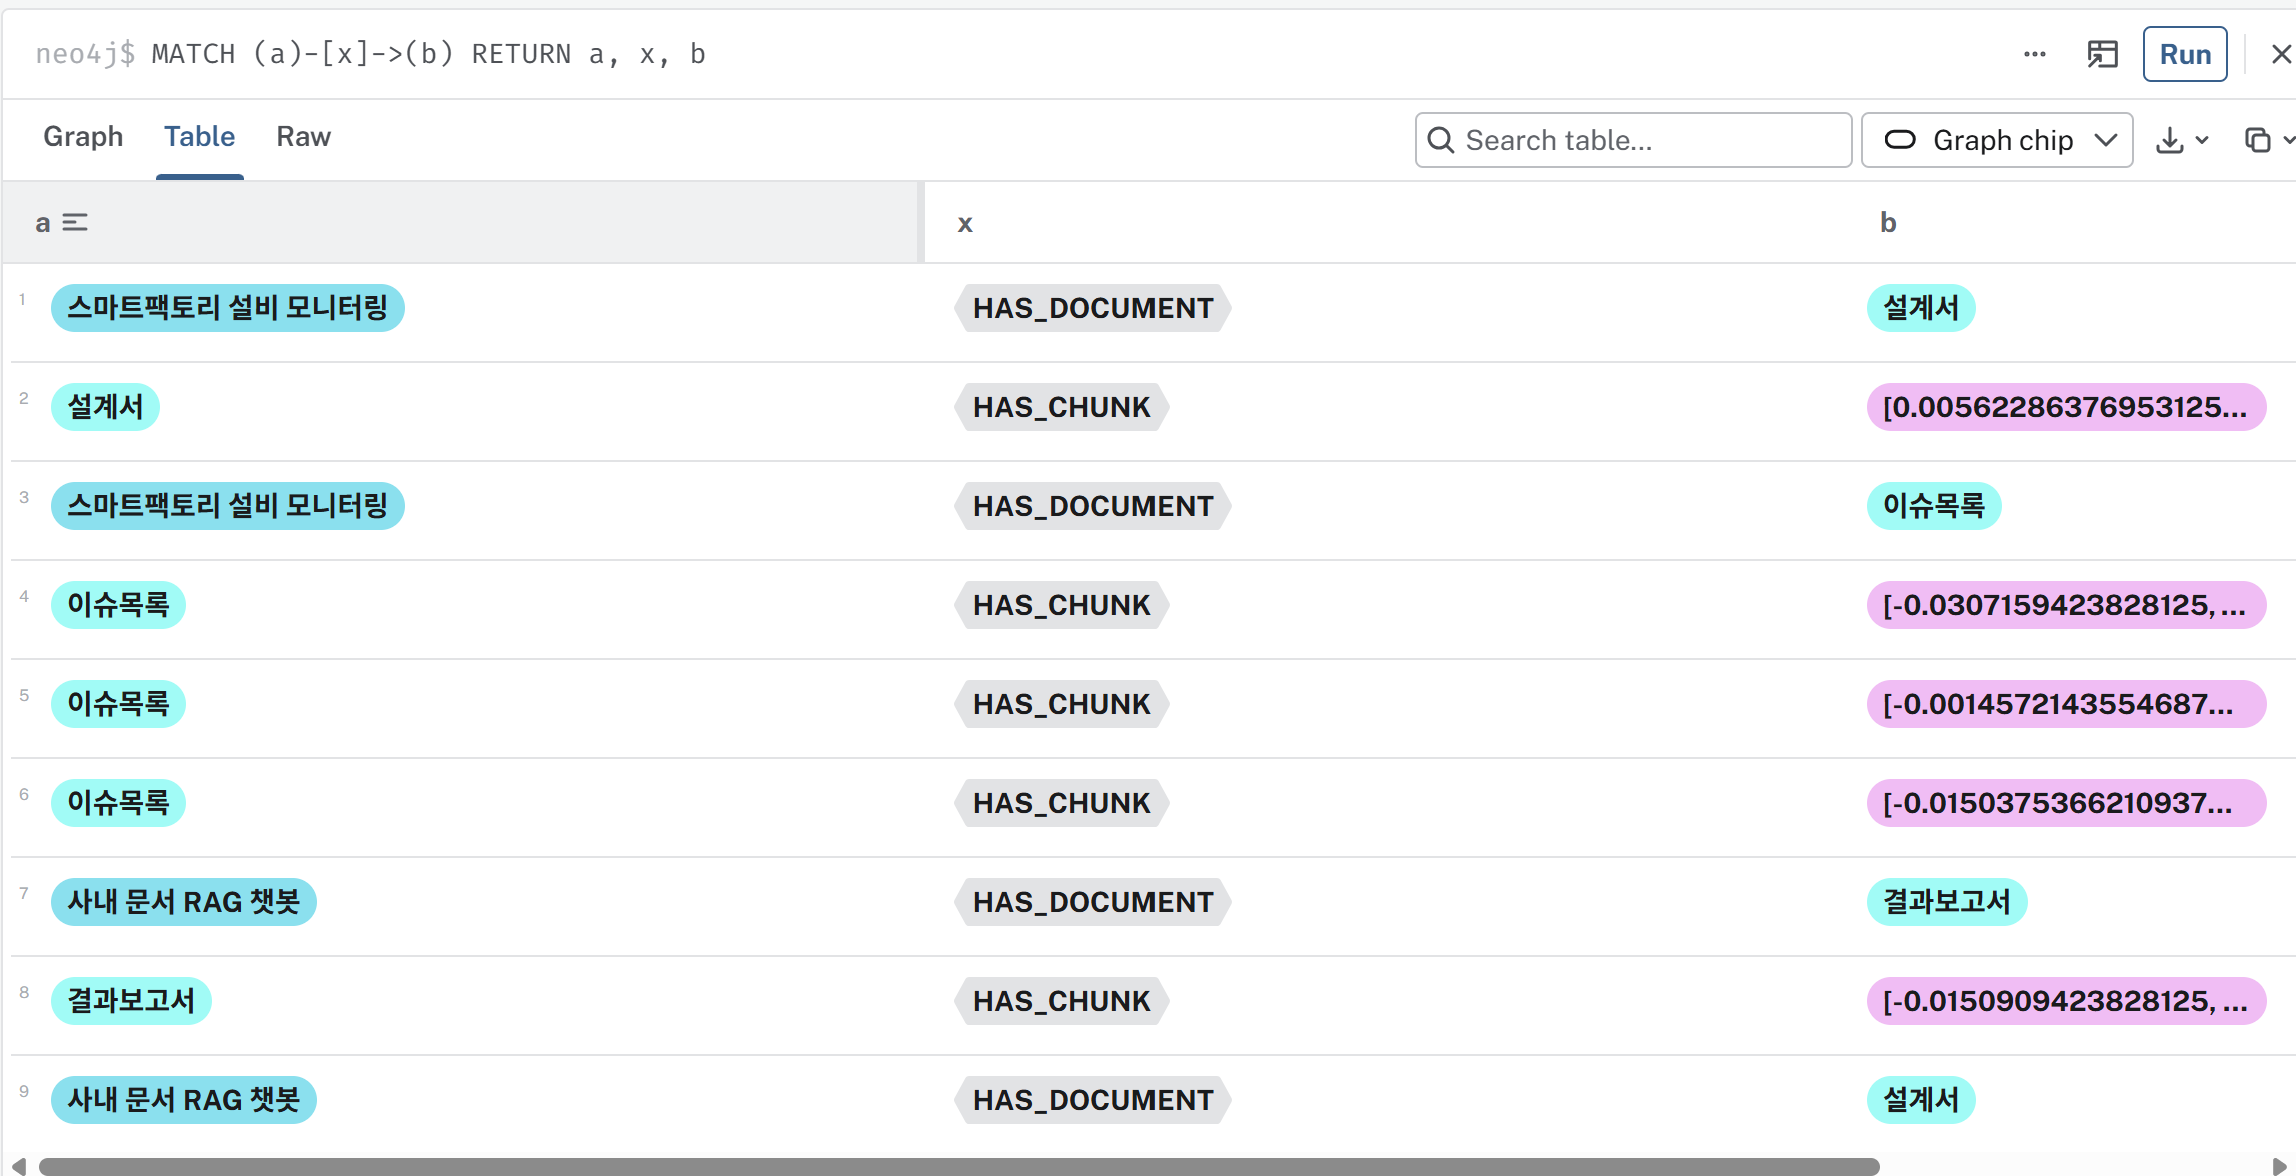

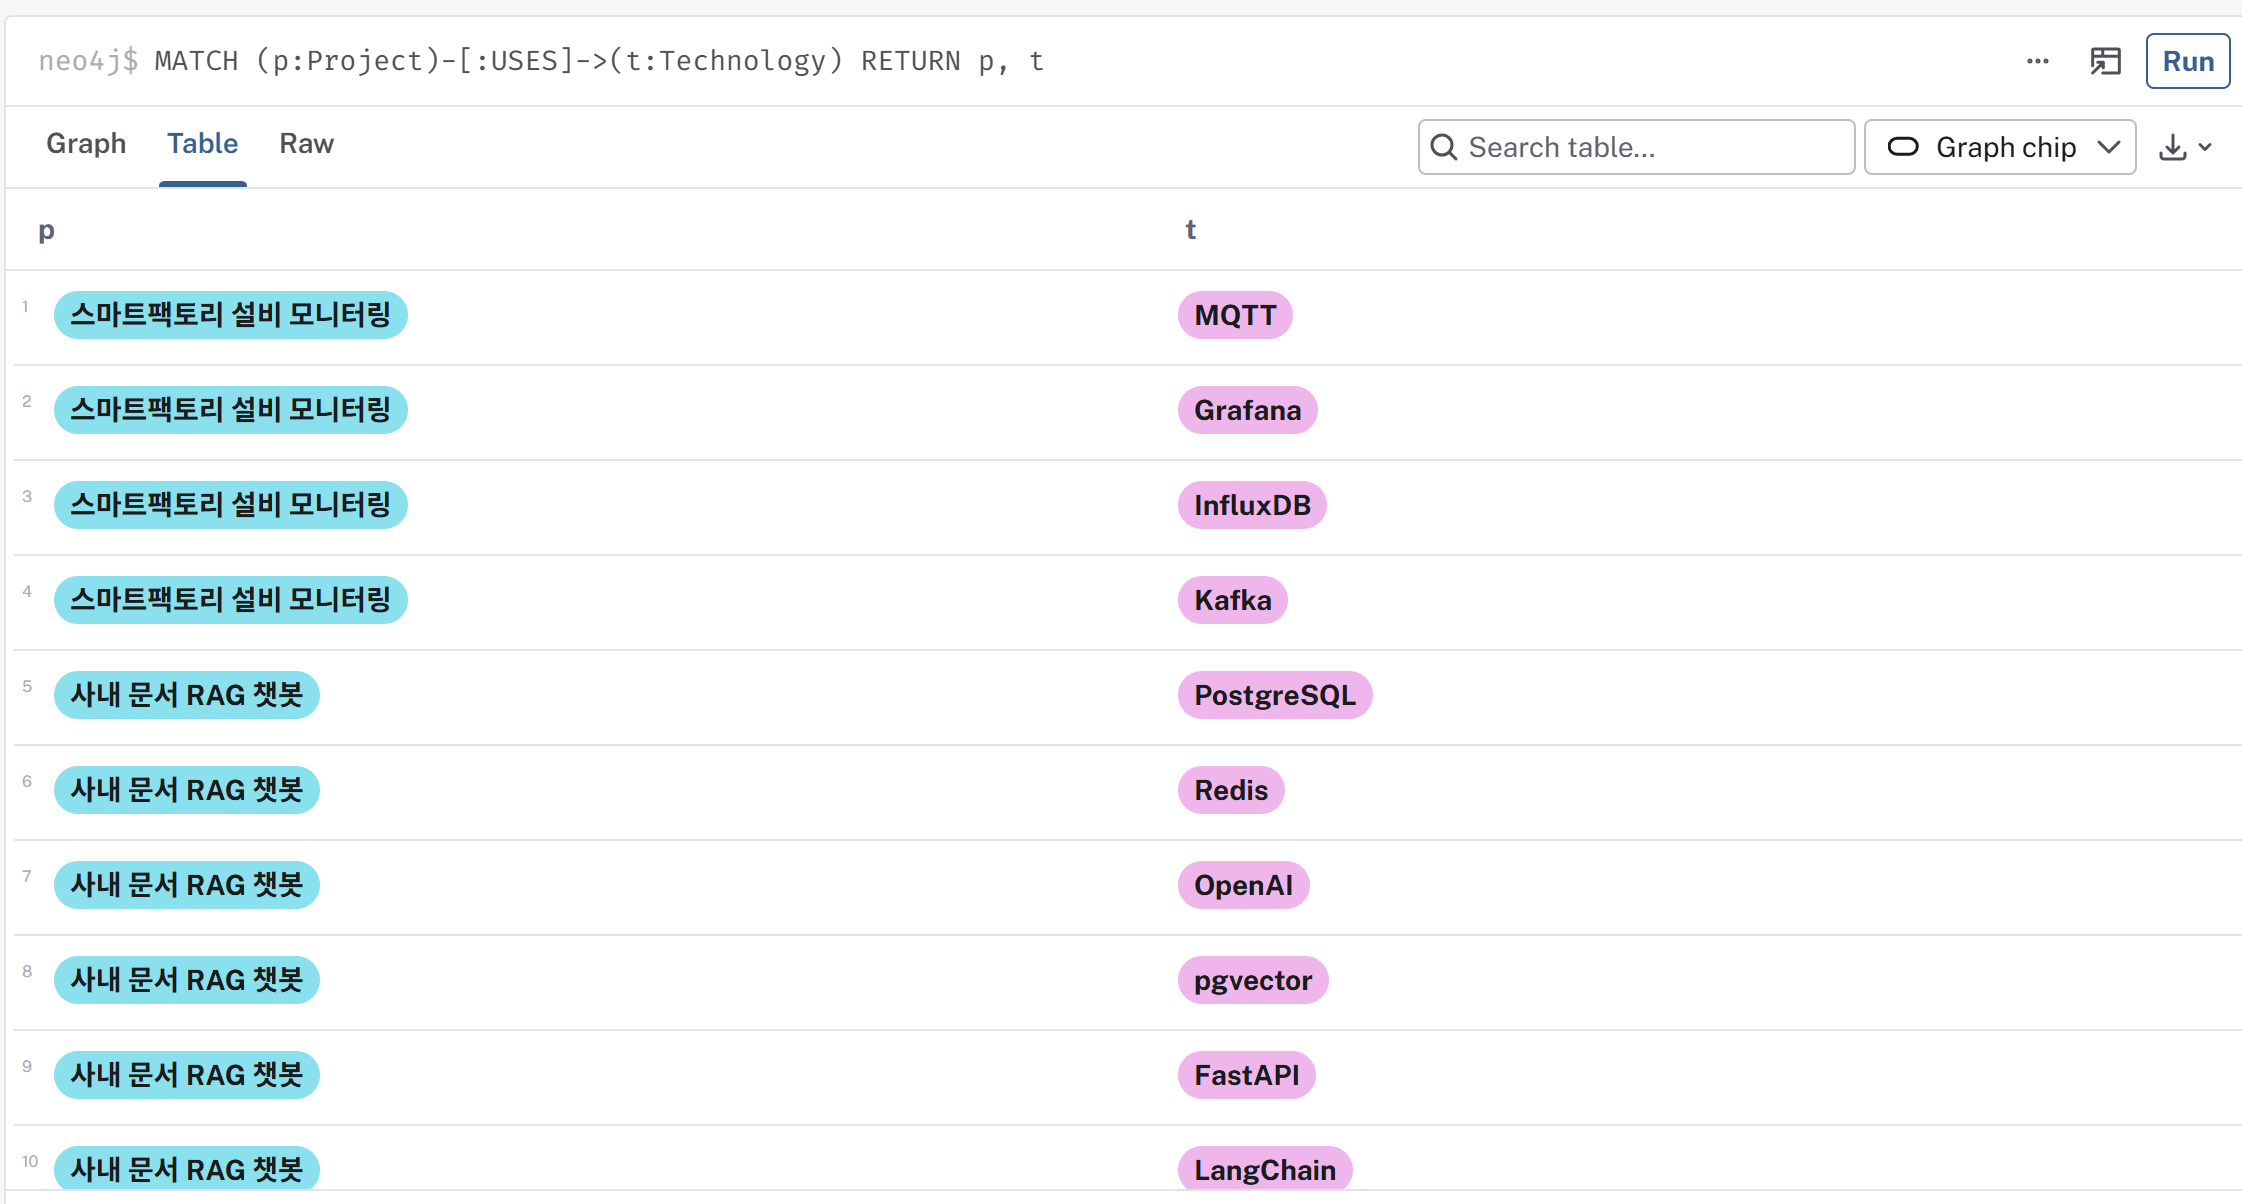

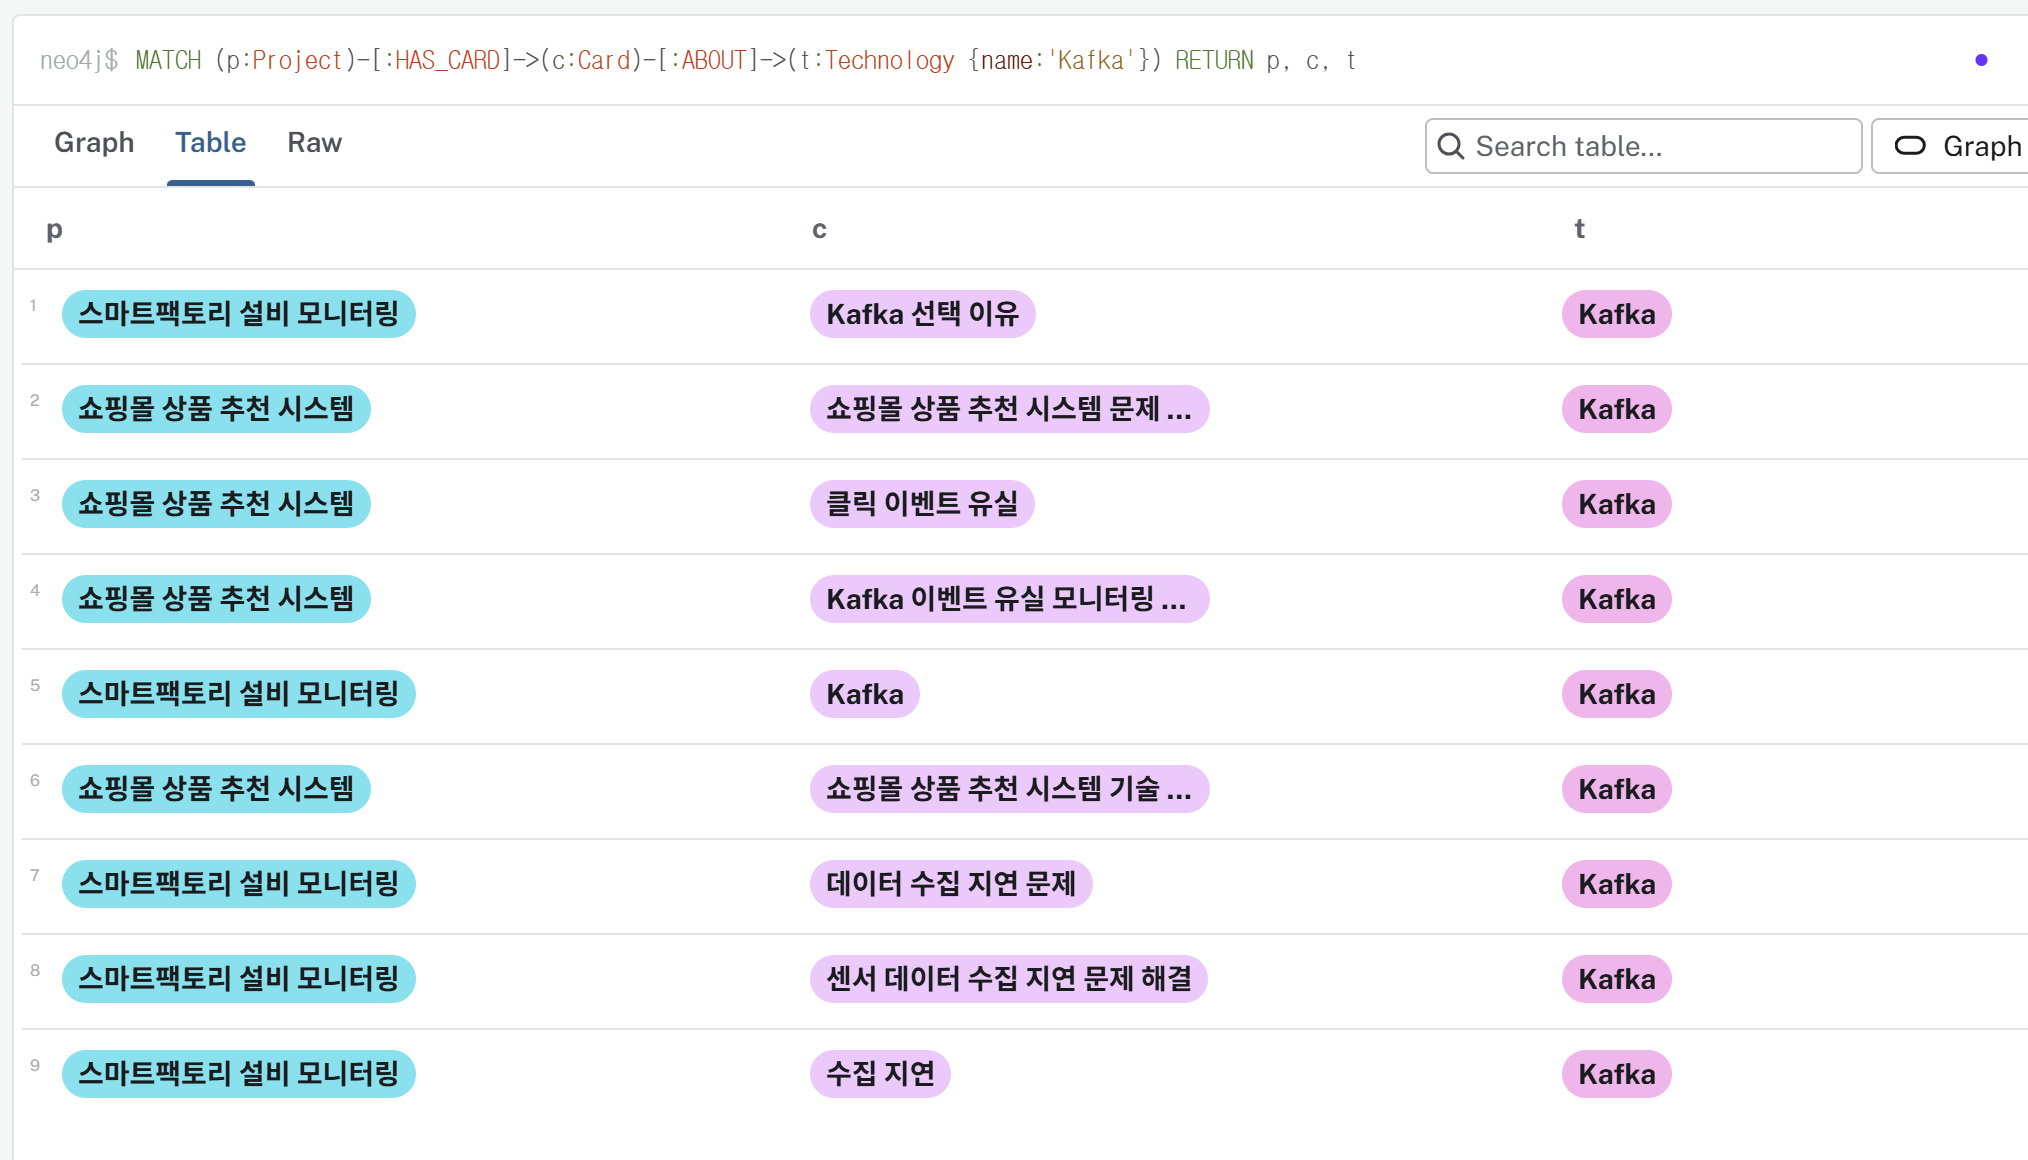

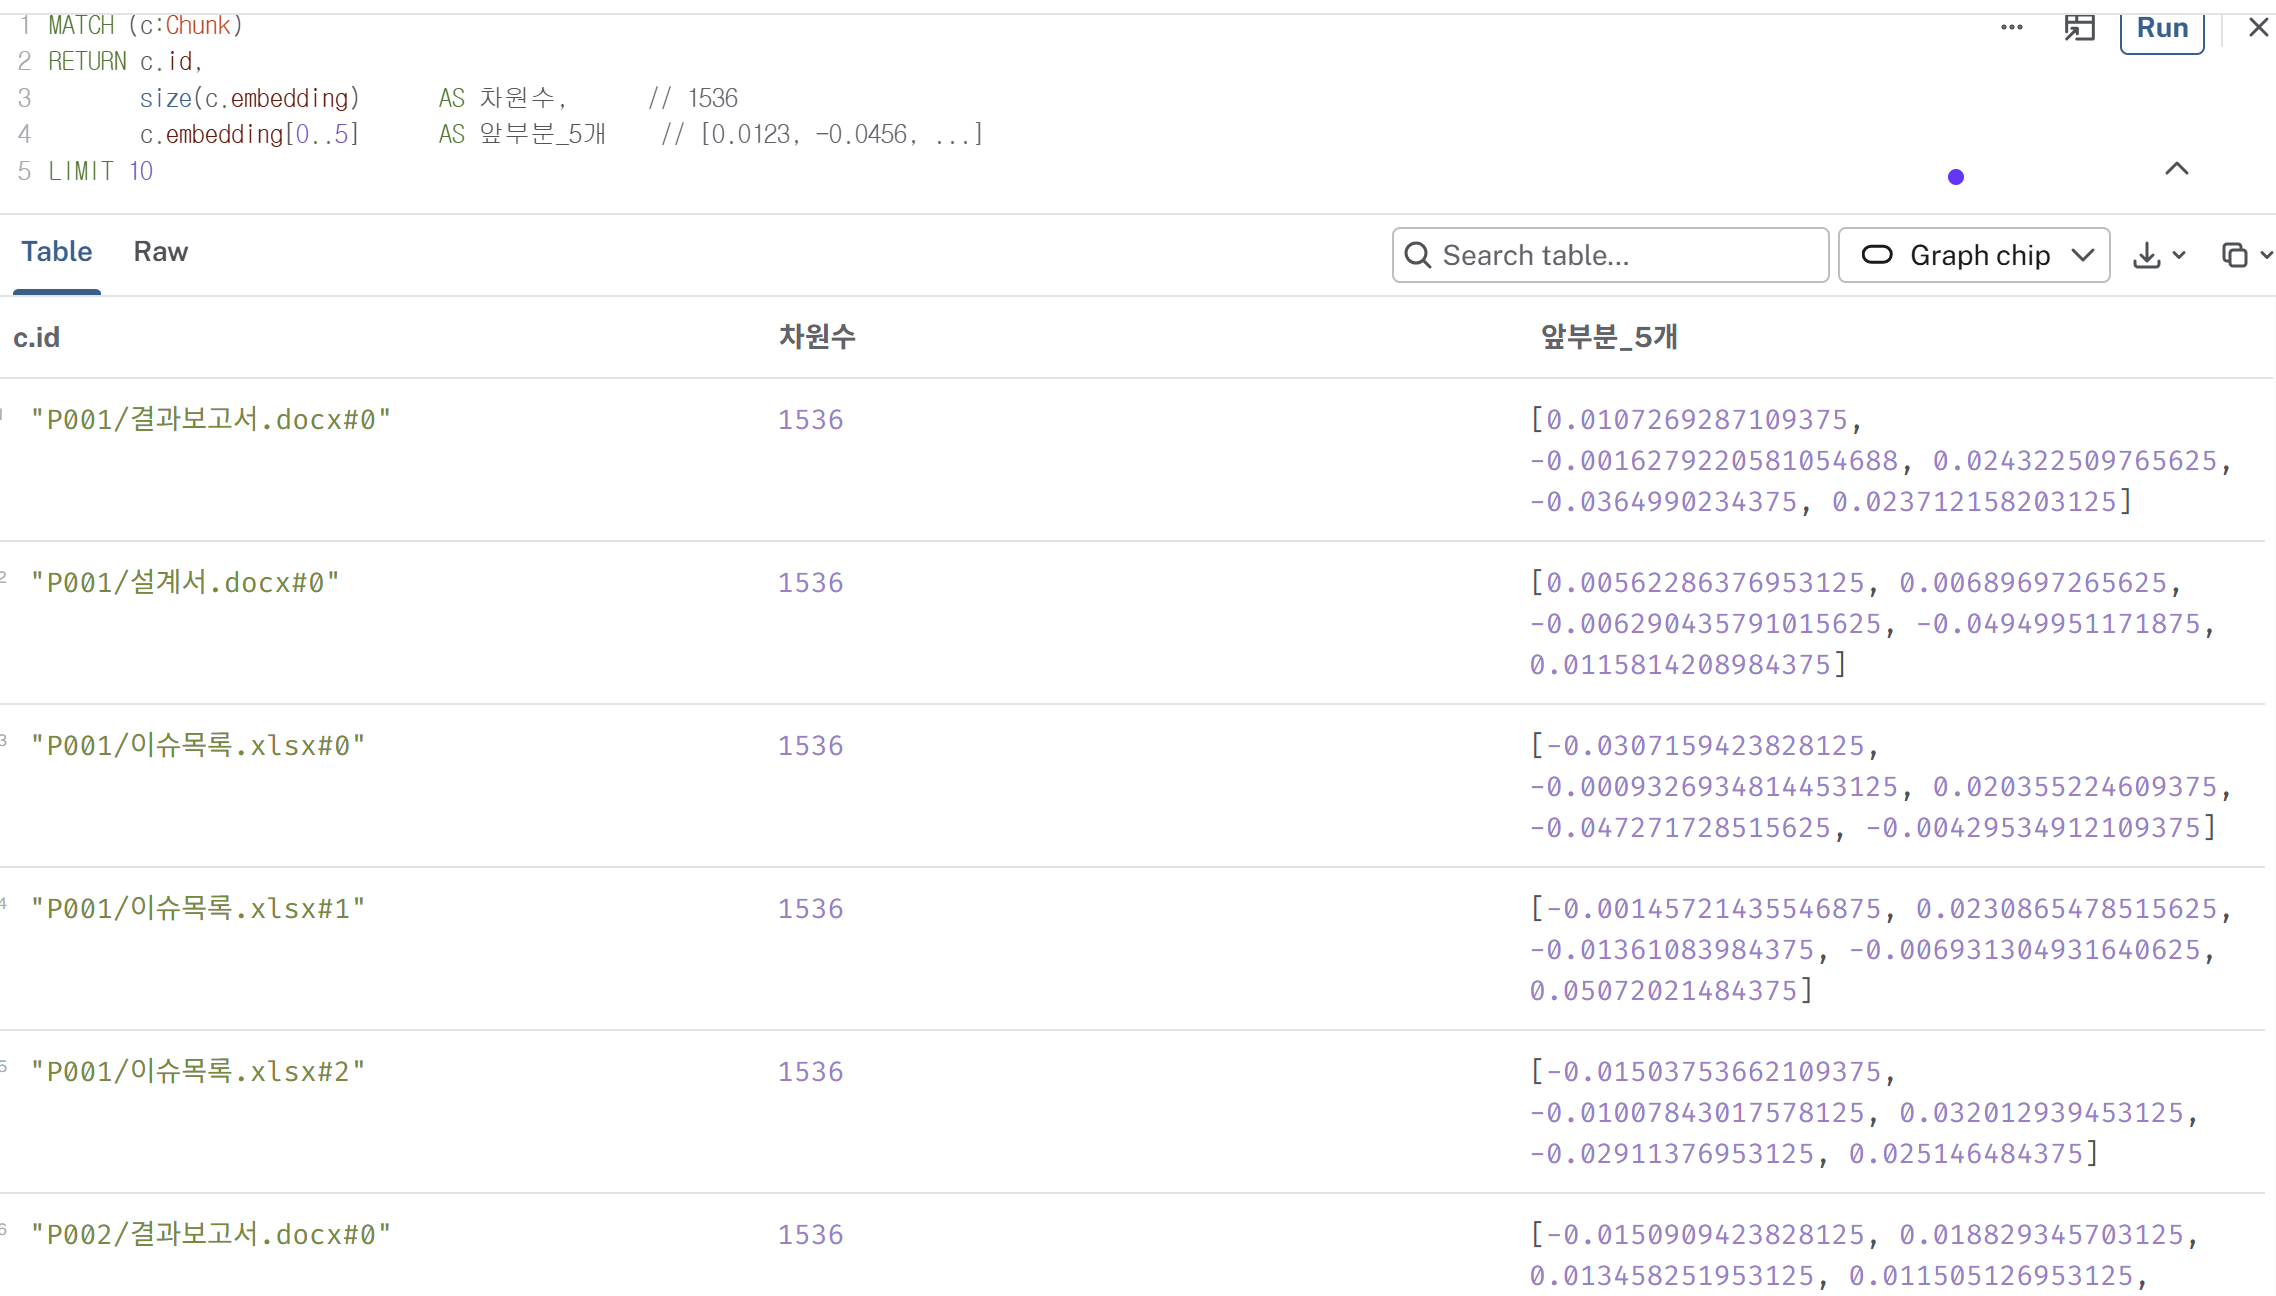

## Neo4j 임베딩 확인 방법 (Neo4j 2026.01+ / Cypher 25 기준)

| 목적 | Cypher | 비고 |
|---|---|---|
| 차원 수와 앞부분 값 | `MATCH (c:Chunk) RETURN c.id, size(c.embedding) AS dims, c.embedding[0..5] AS head LIMIT 5` | `[0..5]` = 앞 5개 슬라이싱 |
| 전체 값 | `MATCH (c:Chunk {id:'P001/이슈목록.xlsx#0'}) RETURN c.embedding` | 결과를 **Table / Text** 탭으로 보기 |
| 누락·차원 이상 점검 | `MATCH (c:Chunk) RETURN count(c) AS total, count(c.embedding) AS has_emb, count(CASE WHEN size(c.embedding) <> 1536 THEN 1 END) AS bad_dim` | `count(속성)`은 null을 세지 않음 |
| 인덱스 상태 | `SHOW VECTOR INDEXES` | `state` = ONLINE, `populationPercent` = 100이면 준비 완료 |
| 두 청크의 유사도 | `MATCH (a:Chunk {id:'P001/이슈목록.xlsx#0'}), (b:Chunk {id:'P003/이슈목록.xlsx#2'}) RETURN vector.similarity.cosine(a.embedding, b.embedding) AS sim` | 1에 가까울수록 비슷 |
| 비슷한 청크 찾기 | 아래 `SEARCH` 쿼리 | 벡터 인덱스 사용 (빠른 근사 검색) |

#### 비슷한 청크 찾기 — `SEARCH` 절

```cypher
CYPHER 25
MATCH (c:Chunk {id: 'P001/이슈목록.xlsx#0'})
MATCH (node:Chunk)
  SEARCH node IN (
    VECTOR INDEX chunk_embedding
    FOR c.embedding
    LIMIT 4
  ) SCORE AS score
WITH c, node, score
WHERE node <> c
RETURN node.id, left(node.text, 40) AS preview, round(score, 3) AS score
```

| 부분 | 뜻 |
|---|---|
| `CYPHER 25` | Cypher 25 문법으로 실행 (DB 기본 언어가 Cypher 5여도 동작) |
| `MATCH (node:Chunk)` | 검색 대상 노드를 변수 `node`로 지정 (인덱스의 라벨과 같아야 함) |
| `SEARCH node IN (VECTOR INDEX ...)` | 벡터 인덱스로 `node` 후보를 찾음 |
| `FOR c.embedding` | 이 벡터와 비슷한 것을 찾음 (보통은 `$vec` 파라미터) |
| `LIMIT 4` | 상위 4개 (자기 자신 포함이라 1개 더) |
| `SCORE AS score` | 유사도 점수를 `score`로 받음 |
| `WITH ... WHERE node <> c` | 자기 자신 제외 |

In [13]:
# 기술을 공유하는 프로젝트 쌍 (그래프가 잘 만들어졌는지 확인)
run('''
MATCH (a:Project)-[:USES]->(t:Technology)<-[:USES]-(b:Project)
WHERE a.id < b.id
RETURN a.name AS project_a, b.name AS project_b, collect(t.name) AS shared_tech
''')

[{'project_a': '사내 문서 RAG 챗봇',
  'project_b': '쇼핑몰 상품 추천 시스템',
  'shared_tech': ['Redis', 'FastAPI']},
 {'project_a': '스마트팩토리 설비 모니터링',
  'project_b': '쇼핑몰 상품 추천 시스템',
  'shared_tech': ['Kafka']}]

**📝 정리** — 기술을 공유하는 프로젝트 쌍: RAG 챗봇 ↔ 추천 시스템 [Redis, FastAPI], 스마트팩토리 ↔ 추천 시스템 [Kafka]. 이 연결이 유사 프로젝트 추천의 근거가 된다.

---
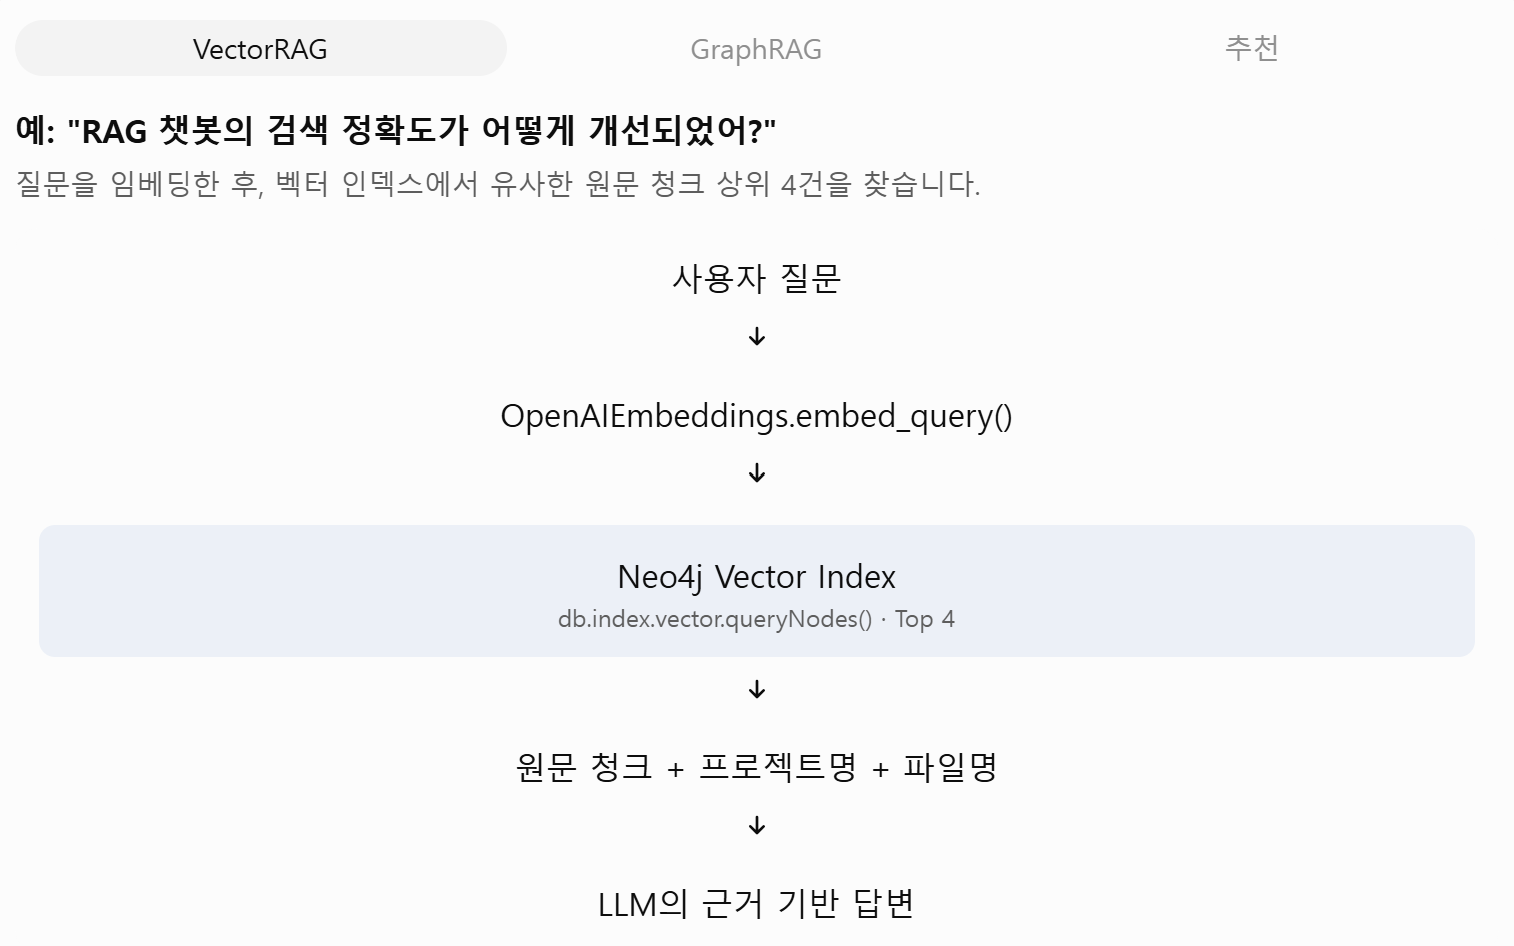

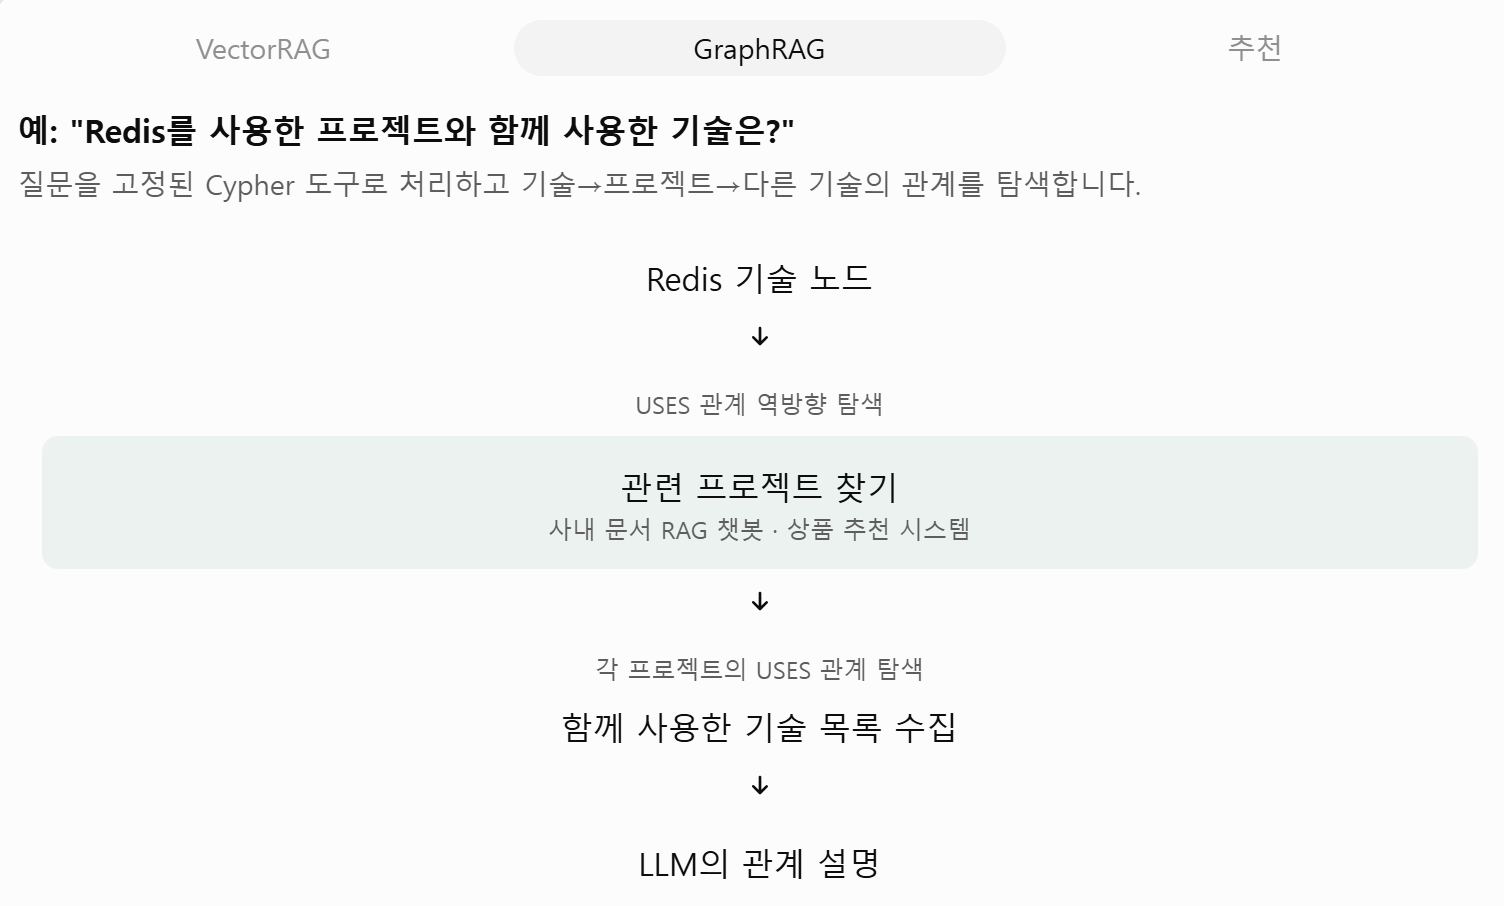

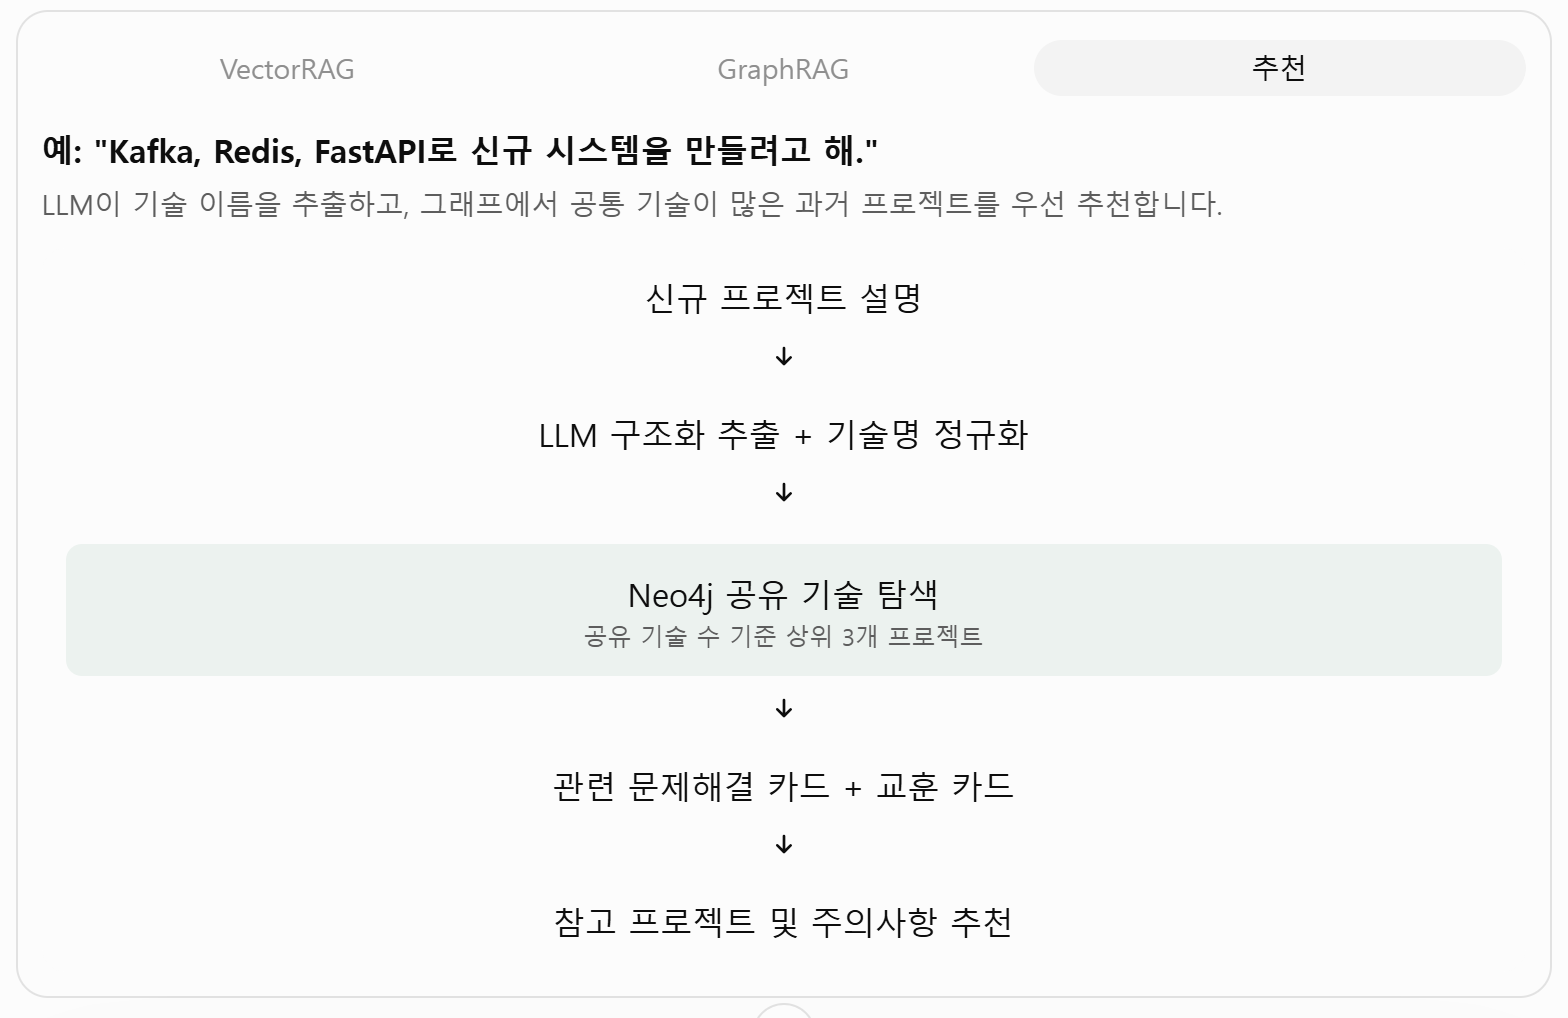

### 5. 에이전트 도구 만들기
에이전트가 쓸 도구 5개입니다. **Cypher는 미리 검증해 두고, LLM은 도구와 파라미터만 고릅니다.**

| 도구 | 역할 | 검색 방식 | 이런 질문에 |
|---|---|---|---|
| `search_documents` | 원문 검색 (RAG) | **벡터** | "RAG 챗봇은 검색 정확도를 어떻게 올렸어?" |
| `search_knowledge_cards` | 카드 필터 검색 | 그래프 (기술·유형·키워드) | "Kafka 문제 해결 사례 알려줘", "교훈만 모아줘" |
| `get_project_overview` | 프로젝트 요약 | 그래프 | "추천 시스템 프로젝트 개요 알려줘" |
| `find_related_by_technology` | 기술 기준 연결 탐색 | 그래프 (**2홉**) | "Redis 쓴 프로젝트와 같이 쓴 기술은?" |
| `recommend_for_new_project` | 신규 프로젝트 추천 | LLM(기술 추출) + 그래프 | "새 프로젝트를 시작하는데 참고할 것은?" |

모든 도구는 결과에 **프로젝트명과 파일명**을 함께 돌려줍니다. 에이전트는 이걸로 출처를 표시합니다.

In [14]:
from langchain_core.tools import tool                                             # [LangChain]


@tool
def search_documents(query: str) -> list[dict]:
    "프로젝트 산출물 원문(설계서·결과보고서·이슈목록)에서 질문과 비슷한 내용을 찾는다. 구체적인 설명이나 수치가 필요할 때 쓴다."
    rows = run('''
        CALL db.index.vector.queryNodes('chunk_embedding', 4, $vec) YIELD node, score
        MATCH (p:Project)-[:HAS_DOCUMENT]->(d:Document)-[:HAS_CHUNK]->(node)
        RETURN p.name AS project, d.file AS file, node.text AS text, score
        ORDER BY score DESC
    ''', vec=embedder.embed_query(query))
    return [{**r, "score": round(r["score"], 3)} for r in rows]


@tool
def search_knowledge_cards(technology: str | None = None,
                           card_type: Literal["적용기술", "문제해결", "교훈"] | None = None,
                           keyword: str | None = None) -> list[dict]:
    "지식 카드를 기술명·카드 유형·키워드로 찾는다. 조건은 필요한 것만 넣는다. 문제 해결 사례나 교훈을 모을 때 쓴다."
    return run('''
        MATCH (p:Project)-[:HAS_CARD]->(c:Card)-[:FROM_CHUNK]->(:Chunk)<-[:HAS_CHUNK]-(d:Document)
        WHERE ($card_type IS NULL OR c.card_type = $card_type)
          AND ($keyword IS NULL OR c.title CONTAINS $keyword OR c.summary CONTAINS $keyword)
        OPTIONAL MATCH (c)-[:ABOUT]->(t:Technology)
        WITH p, d, c, collect(t.name) AS techs
        WHERE $technology IS NULL OR $technology IN techs
        RETURN p.name AS project, d.file AS file, c.card_type AS card_type, c.title AS title,
               c.summary AS summary, c.problem AS problem, c.solution AS solution, techs
        LIMIT 10
    ''', technology=normalize_tech(technology) if technology else None, card_type=card_type, keyword=keyword)


@tool
def get_project_overview(project_name: str) -> list[dict]:
    "프로젝트 이름(일부만 써도 됨)으로 분야·연도·요약·사용 기술·산출물·카드 수를 조회한다."
    return run('''
        MATCH (p:Project) WHERE p.name CONTAINS $name OR p.id = $name
        OPTIONAL MATCH (p)-[:USES]->(t:Technology)
        WITH p, collect(DISTINCT t.name) AS technologies
        OPTIONAL MATCH (p)-[:HAS_DOCUMENT]->(d:Document)
        WITH p, technologies, collect(DISTINCT d.file) AS documents
        OPTIONAL MATCH (p)-[:HAS_CARD]->(c:Card)
        RETURN p.name AS project, p.domain AS domain, p.year AS year, p.summary AS summary,
               technologies, documents, collect(c.card_type) AS card_types
    ''', name=project_name)


@tool
def find_related_by_technology(technology: str) -> list[dict]:
    "특정 기술을 쓴 프로젝트와, 그 프로젝트들에서 함께 쓴 기술을 찾는다. (기술 → 프로젝트 → 다른 기술, 2홉)"
    return run('''
        MATCH (t:Technology {name: $tech})<-[:USES]-(p:Project)
        OPTIONAL MATCH (p)-[:USES]->(other:Technology) WHERE other <> t
        RETURN p.name AS project, p.domain AS domain, collect(other.name) AS used_together
    ''', tech=normalize_tech(technology))


class NewProject(BaseModel):
    technologies: list[str] = Field(description="설명에 나온 기술 이름")


tech_extractor = llm.with_structured_output(NewProject)


@tool
def recommend_for_new_project(description: str) -> dict:
    "신규 프로젝트 설명을 받아, 기술이 겹치는 과거 프로젝트와 참고할 문제해결·교훈 카드를 추천한다."
    techs = normalize_techs(tech_extractor.invoke(
        f"다음 프로젝트 설명에서 기술 이름만 뽑아라. 표기는 가능하면 이 목록을 따른다: {', '.join(KNOWN_TECH)}\n\n{description}"
    ).technologies)
    rows = run('''
        MATCH (p:Project)-[:USES]->(t:Technology) WHERE t.name IN $techs
        WITH p, collect(t.name) AS shared
        ORDER BY size(shared) DESC LIMIT 3
        MATCH (p)-[:HAS_CARD]->(c:Card)-[:FROM_CHUNK]->(:Chunk)<-[:HAS_CHUNK]-(d:Document)
        OPTIONAL MATCH (c)-[:ABOUT]->(ct:Technology)
        WITH p, shared, c, d, collect(ct.name) AS card_techs
        RETURN p.name AS project, shared,
               collect({card_type: c.card_type, title: c.title, summary: c.summary, file: d.file, techs: card_techs}) AS cards
        ORDER BY size(shared) DESC
    ''', techs=techs)
    for r in rows:                                    # 공유 기술 관련 문제해결 + 모든 교훈만 남긴다
        r["cards"] = [c for c in r["cards"]
                      if c["card_type"] == "교훈" or (c["card_type"] == "문제해결" and set(c["techs"]) & set(techs))]
    return {"extracted_technologies": techs, "similar_projects": rows}


TOOLS = [search_documents, search_knowledge_cards, get_project_overview, find_related_by_technology, recommend_for_new_project]

### 도구를 하나씩 먼저 테스트
에이전트에 넣기 전에 **도구 단위로 결과를 확인**하면, 문제가 생겼을 때 "도구 문제인지 에이전트 판단 문제인지"를 쉽게 구분할 수 있습니다.

In [15]:
import json
show = lambda x: print(json.dumps(x, ensure_ascii=False, indent=2)[:1500])

print("① search_documents"); show(search_documents.invoke({"query": "검색 정확도를 높인 방법"}))

① search_documents


Received notification from DBMS server: <GqlStatusObject gql_status='01N01', status_description='warn: feature deprecated with replacement. db.index.vector.queryNodes is deprecated. It is replaced by SEARCH.', position=<SummaryInputPosition line=2, column=9, offset=9>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 9, 'line': 2, 'column': 9}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n        CALL db.index.vector.queryNodes('chunk_embedding', 4, $vec) YIELD node, score\n        MATCH (p:Project)-[:HAS_DOCUMENT]->(d:Document)-[:HAS_CHUNK]->(node)\n        RETURN p.name AS project, d.file AS file, node.text AS text, score\n        ORDER BY score DESC\n    "


[
  {
    "project": "사내 문서 RAG 챗봇",
    "file": "이슈목록.xlsx",
    "text": "[이슈 I-01] 코드 검색 실패\n현상: 'HR-204' 질문에 엉뚱한 문서를 답변\n원인: 벡터 검색은 코드 같은 정확한 문자열에 약함\n해결: BM25 + 벡터 하이브리드 검색 적용\n관련기술: pgvector, BM25",
    "score": 0.728
  },
  {
    "project": "사내 문서 RAG 챗봇",
    "file": "결과보고서.docx",
    "text": "## 사내 문서 RAG 챗봇 결과보고서\n## 수행 결과\n평가 질문 200개 기준 답변 정확도 82%를 달성했다.\n## 주요 문제 해결\n사내 약어와 'HR-204' 같은 규정 코드를 묻는 질문의 검색 정확도가 낮았다. 벡터 검색은 정확한 문자열 매칭에 약하기 때문이다. BM25 키워드 검색과 벡터 검색을 결합한 하이브리드 검색을 적용해 정확도를 64%에서 82%로 높였다.\n## 교훈\n평가 질문셋을 프로젝트 후반에 만들어 개선 효과를 수치로 확인하기 어려웠다. 프로젝트 초기에 평가셋부터 만들어야 한다.",
    "score": 0.702
  },
  {
    "project": "사내 문서 RAG 챗봇",
    "file": "이슈목록.xlsx",
    "text": "[이슈 I-02] 표 내용 누락\n현상: PDF 표 안의 수치를 답변하지 못함\n원인: 텍스트 추출 시 표 구조가 깨짐\n해결: 표를 별도로 추출해 마크다운 표로 저장\n관련기술: LangChain",
    "score": 0.651
  },
  {
    "project": "사내 문서 RAG 챗봇",
    "file": "설계서.docx",
    "text": "## 사내 문서 RAG 챗봇 설계서\n## 개요\n사내 규정과 업무 매뉴얼 약 3,000건을 대상으로 직원 질문에 답하는 챗봇을 구축한다.\n## 아키텍처\n문서를 LangChain으

**📝 정리** — 도구는 정상 동작하지만 `db.index.vector.queryNodes`라 deprecated 경고가 나온다. 4장에서 본 `SEARCH` 절로 바꿀 수 있다.

In [16]:
print("② search_knowledge_cards (Kafka 문제해결)")
show(search_knowledge_cards.invoke({"technology": "카프카", "card_type": "문제해결"}))     # '카프카' → 'Kafka' 정규화

② search_knowledge_cards (Kafka 문제해결)
[
  {
    "project": "스마트팩토리 설비 모니터링",
    "file": "결과보고서.docx",
    "card_type": "문제해결",
    "title": "센서 데이터 수집 지연 문제 해결",
    "summary": "운영 2주 차에 센서 데이터 수집 지연이 발생하여 Kafka 파티션 수를 늘리고 수집기를 확장하여 문제를 해결했다.",
    "problem": "운영 2주 차에 센서 데이터 수집 지연이 최대 30초까지 발생했다.",
    "solution": "Kafka 토픽 파티션을 6개로 늘리고 수집기를 컨슈머 그룹으로 3대까지 확장하여 지연을 1초 이내로 줄였다.",
    "techs": [
      "Kafka"
    ]
  },
  {
    "project": "스마트팩토리 설비 모니터링",
    "file": "설계서.docx",
    "card_type": "문제해결",
    "title": "데이터 수집 지연 문제",
    "summary": "데이터 수집 지연이 2초 이내로 유지되어야 하는 비기능 요구사항이 있었다.",
    "problem": "데이터 수집 지연이 2초를 초과할 경우 실시간 모니터링에 문제가 발생할 수 있다.",
    "solution": "MQTT 브로커와 Kafka를 통해 데이터 전송 경로를 최적화하여 지연을 최소화했다.",
    "techs": [
      "Kafka",
      "MQTT"
    ]
  },
  {
    "project": "스마트팩토리 설비 모니터링",
    "file": "이슈목록.xlsx",
    "card_type": "문제해결",
    "title": "수집 지연",
    "summary": "센서 데이터가 최대 30초 늦게 저장됨 — 원인: Kafka 파티션 1개로 병렬 처리 불가 → 해결: 파티션 6개로 증설, 컨슈머 3대 확장",
    "proble

**📝 정리** — `카프카`로 물어도 `normalize_tech`가 `Kafka`로 바꿔 찾았다.

In [17]:
print("③ get_project_overview");      show(get_project_overview.invoke({"project_name": "추천"}))
print("\n④ find_related_by_technology"); show(find_related_by_technology.invoke({"technology": "Redis"}))

③ get_project_overview
[
  {
    "project": "쇼핑몰 상품 추천 시스템",
    "domain": "커머스",
    "year": 2025,
    "summary": "회원 50만 명 쇼핑몰의 클릭·구매 이력 기반 개인화 상품 추천 시스템",
    "technologies": [
      "Redis",
      "FastAPI",
      "Kafka",
      "Spark"
    ],
    "documents": [
      "이슈목록.xlsx",
      "설계서.docx",
      "결과보고서.docx"
    ],
    "card_types": [
      "문제해결",
      "교훈",
      "적용기술",
      "교훈",
      "문제해결",
      "문제해결",
      "교훈",
      "적용기술",
      "문제해결",
      "문제해결"
    ]
  }
]

④ find_related_by_technology
[
  {
    "project": "쇼핑몰 상품 추천 시스템",
    "domain": "커머스",
    "used_together": [
      "FastAPI",
      "Kafka",
      "Spark"
    ]
  },
  {
    "project": "사내 문서 RAG 챗봇",
    "domain": "사무",
    "used_together": [
      "OpenAI",
      "BM25",
      "FastAPI",
      "PostgreSQL",
      "pgvector",
      "LangChain"
    ]
  }
]


In [18]:
print("⑤ recommend_for_new_project")
show(recommend_for_new_project.invoke({"description": "물류센터 IoT 센서 데이터를 Kafka로 실시간 수집하고, FastAPI 조회 API에 Redis 캐시를 둘 예정"}))

⑤ recommend_for_new_project
{
  "extracted_technologies": [
    "FastAPI",
    "Kafka",
    "Redis"
  ],
  "similar_projects": [
    {
      "project": "쇼핑몰 상품 추천 시스템",
      "shared": [
        "FastAPI",
        "Kafka",
        "Redis"
      ],
      "cards": [
        {
          "summary": "다음 프로젝트에서 기억해야 할 점.",
          "file": "설계서.docx",
          "card_type": "교훈",
          "title": "쇼핑몰 상품 추천 시스템 교훈",
          "techs": []
        },
        {
          "summary": "모델의 오프라인 평가 지표가 높았던 것과 실제 클릭률의 차이를 인지하고 A/B 테스트의 필요성을 깨달았다.",
          "file": "결과보고서.docx",
          "card_type": "교훈",
          "title": "A/B 테스트의 중요성",
          "techs": []
        },
        {
          "summary": "평균 응답 900ms — 원인: 요청마다 모델 계산 → 해결: 사전 계산 결과를 Redis에 저장",
          "file": "이슈목록.xlsx",
          "card_type": "문제해결",
          "title": "추천 API 지연",
          "techs": [
            "FastAPI",
            "Redis"
          ]
        },
        {
          "summary": "Kafka 이벤트 유실을 늦게 발견하여 수집 

**📝 정리** — 추천 1순위 프로젝트(공유 기술 3개)의 첫 카드가 내용 없는 교훈 카드였다. 잘못된 카드는 추천 결과에도 그대로 섞인다.

---
### 6. 지식 자산화 에이전트
`create_agent`에 도구 5개를 주고, **출처 표시 규칙**과 **도구 선택 기준**을 시스템 프롬프트에 적습니다. `InMemorySaver`로 대화 기억을 붙여 이어서 질문할 수 있게 합니다.

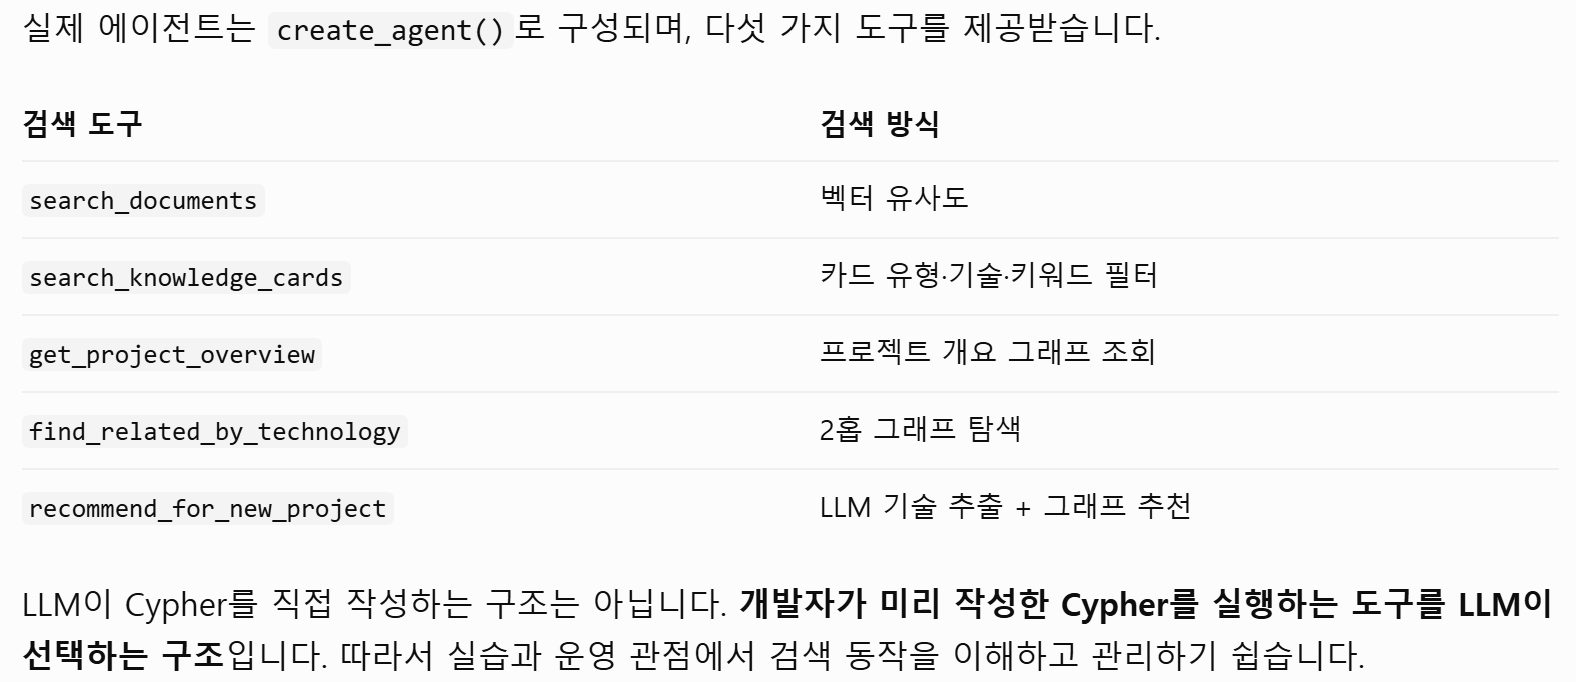

In [19]:
from langchain.agents import create_agent                                          # [LangChain]
from langchain.agents.middleware import ModelCallLimitMiddleware
from langgraph.checkpoint.memory import InMemorySaver                              # [LangGraph] 대화 기억

SYSTEM_PROMPT = '''너는 회사의 '기술 지식 자산화 도우미'다. 과거 프로젝트 산출물로 만든 지식 베이스에서 답한다.

[도구 선택]
- 특정 기술의 문제 해결 사례, 교훈, 적용 기술 목록 → search_knowledge_cards
- 구체적 설명·수치·원문 근거 → search_documents
- 프로젝트 하나의 개요 → get_project_overview
- 어떤 기술을 쓴 프로젝트, 함께 쓴 기술 → find_related_by_technology
- 새 프로젝트 설명을 주며 참고할 것을 물으면 → recommend_for_new_project
- 필요하면 여러 도구를 이어서 써라.

[답변 규칙]
- 반드시 도구 결과에 있는 내용만 쓴다. 없으면 "지식 베이스에서 찾지 못했습니다"라고 말한다.
- 사실마다 끝에 출처를 붙인다. 형식: (출처: 프로젝트명 / 파일명)
- 문제 해결 사례는 '문제 → 원인 → 해결' 순서로 정리한다.
- 한국어로 간결하게 답한다.'''

kb_agent = create_agent(
    model=llm,
    tools=TOOLS,
    system_prompt=SYSTEM_PROMPT,
    middleware=[ModelCallLimitMiddleware(run_limit=8, exit_behavior="end")],   # 도구를 무한히 부르지 않게
    checkpointer=InMemorySaver(),                                              # thread_id 별 대화 기억
)


def ask(question: str, thread_id: str = "notebook", show_tools: bool = True) -> str:
    result = kb_agent.invoke({"messages": [("user", question)]},
                             config={"configurable": {"thread_id": thread_id}})
    if show_tools:                                             # 이번 질문(마지막 사용자 메시지 이후)에서 부른 도구 표시
        msgs = result["messages"]
        last_user = max(i for i, m in enumerate(msgs) if m.type == "human")
        called = [tc["name"] for m in msgs[last_user:] for tc in getattr(m, "tool_calls", []) or []]
        print("🔧 사용한 도구:", ", ".join(called) or "없음")
    answer = result["messages"][-1].text
    print("💬", answer)
    return answer

In [20]:
ask("Kafka 관련해서 과거 프로젝트에서 어떤 문제가 있었고 어떻게 해결했어?")

🔧 사용한 도구: search_knowledge_cards
💬 과거 프로젝트에서 Kafka와 관련된 문제 해결 사례는 다음과 같습니다.

1. **스마트팩토리 설비 모니터링**
   - **문제**: 운영 2주 차에 센서 데이터 수집 지연이 최대 30초까지 발생했다.
   - **원인**: Kafka 파티션이 1개로 설정되어 병렬 처리가 불가능했다.
   - **해결**: Kafka 토픽의 파티션 수를 6개로 늘리고, 수집기를 컨슈머 그룹으로 3대까지 확장하여 지연을 1초 이내로 줄였다. (출처: 스마트팩토리 설비 모니터링 / 결과보고서.docx)

2. **스마트팩토리 설비 모니터링**
   - **문제**: 데이터 수집 지연이 2초를 초과할 경우 실시간 모니터링에 문제가 발생할 수 있었다.
   - **원인**: 비기능 요구사항으로 데이터 수집 지연이 2초 이내로 유지되어야 했다.
   - **해결**: MQTT 브로커와 Kafka를 통해 데이터 전송 경로를 최적화하여 지연을 최소화했다. (출처: 스마트팩토리 설비 모니터링 / 설계서.docx)

3. **쇼핑몰 상품 추천 시스템**
   - **문제**: 하루 약 3%의 클릭 이벤트가 누락되었다.
   - **원인**: Kafka 프로듀서의 acks 설정이 1로 되어 있었다.
   - **해결**: acks를 all로 변경하고 재시도 설정을 추가하여 이벤트 유실 문제를 해결했다. (출처: 쇼핑몰 상품 추천 시스템 / 이슈목록.xlsx)


'과거 프로젝트에서 Kafka와 관련된 문제 해결 사례는 다음과 같습니다.\n\n1. **스마트팩토리 설비 모니터링**\n   - **문제**: 운영 2주 차에 센서 데이터 수집 지연이 최대 30초까지 발생했다.\n   - **원인**: Kafka 파티션이 1개로 설정되어 병렬 처리가 불가능했다.\n   - **해결**: Kafka 토픽의 파티션 수를 6개로 늘리고, 수집기를 컨슈머 그룹으로 3대까지 확장하여 지연을 1초 이내로 줄였다. (출처: 스마트팩토리 설비 모니터링 / 결과보고서.docx)\n\n2. **스마트팩토리 설비 모니터링**\n   - **문제**: 데이터 수집 지연이 2초를 초과할 경우 실시간 모니터링에 문제가 발생할 수 있었다.\n   - **원인**: 비기능 요구사항으로 데이터 수집 지연이 2초 이내로 유지되어야 했다.\n   - **해결**: MQTT 브로커와 Kafka를 통해 데이터 전송 경로를 최적화하여 지연을 최소화했다. (출처: 스마트팩토리 설비 모니터링 / 설계서.docx)\n\n3. **쇼핑몰 상품 추천 시스템**\n   - **문제**: 하루 약 3%의 클릭 이벤트가 누락되었다.\n   - **원인**: Kafka 프로듀서의 acks 설정이 1로 되어 있었다.\n   - **해결**: acks를 all로 변경하고 재시도 설정을 추가하여 이벤트 유실 문제를 해결했다. (출처: 쇼핑몰 상품 추천 시스템 / 이슈목록.xlsx)'

**📝 정리** — 2번째 사례가 설계서에서 지어낸 카드다. 에이전트는 "원인: 비기능 요구사항으로 2초 이내 유지"라고 출처까지 붙여 답했다. 출처가 있으니 오히려 믿기 쉬워진다.

In [21]:
ask("사내 문서 RAG 챗봇 프로젝트는 검색 정확도를 어떻게 올렸어? 수치도 알려줘.")

Received notification from DBMS server: <GqlStatusObject gql_status='01N01', status_description='warn: feature deprecated with replacement. db.index.vector.queryNodes is deprecated. It is replaced by SEARCH.', position=<SummaryInputPosition line=2, column=9, offset=9>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 9, 'line': 2, 'column': 9}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n        CALL db.index.vector.queryNodes('chunk_embedding', 4, $vec) YIELD node, score\n        MATCH (p:Project)-[:HAS_DOCUMENT]->(d:Document)-[:HAS_CHUNK]->(node)\n        RETURN p.name AS project, d.file AS file, node.text AS text, score\n        ORDER BY score DESC\n    "


🔧 사용한 도구: search_documents
💬 사내 문서 RAG 챗봇 프로젝트에서 검색 정확도를 올린 방법은 다음과 같습니다.

- **문제**: 사내 약어와 'HR-204' 같은 규정 코드를 묻는 질문의 검색 정확도가 낮았다. 초기 정확도는 64%였다.
- **해결**: BM25 키워드 검색과 벡터 검색을 결합한 하이브리드 검색을 적용하여 검색 정확도를 82%로 높였다. (출처: 사내 문서 RAG 챗봇 / 결과보고서.docx)

이로 인해 평가 질문 200개 기준으로 82%의 답변 정확도를 달성했다. (출처: 사내 문서 RAG 챗봇 / 결과보고서.docx)


"사내 문서 RAG 챗봇 프로젝트에서 검색 정확도를 올린 방법은 다음과 같습니다.\n\n- **문제**: 사내 약어와 'HR-204' 같은 규정 코드를 묻는 질문의 검색 정확도가 낮았다. 초기 정확도는 64%였다.\n- **해결**: BM25 키워드 검색과 벡터 검색을 결합한 하이브리드 검색을 적용하여 검색 정확도를 82%로 높였다. (출처: 사내 문서 RAG 챗봇 / 결과보고서.docx)\n\n이로 인해 평가 질문 200개 기준으로 82%의 답변 정확도를 달성했다. (출처: 사내 문서 RAG 챗봇 / 결과보고서.docx)"

**📝 정리** — 원문 검색(`search_documents`)으로 64% → 82% 수치와 출처를 정확히 가져왔다.

In [22]:
ask("Redis를 쓴 프로젝트들과, 그 프로젝트에서 같이 쓴 기술을 알려줘.")

🔧 사용한 도구: find_related_by_technology
💬 Redis를 사용한 프로젝트와 함께 사용된 기술은 다음과 같습니다.

1. **쇼핑몰 상품 추천 시스템**
   - **함께 사용된 기술**: FastAPI, Kafka, Spark

2. **사내 문서 RAG 챗봇**
   - **함께 사용된 기술**: OpenAI, BM25, FastAPI, PostgreSQL, pgvector, LangChain


'Redis를 사용한 프로젝트와 함께 사용된 기술은 다음과 같습니다.\n\n1. **쇼핑몰 상품 추천 시스템**\n   - **함께 사용된 기술**: FastAPI, Kafka, Spark\n\n2. **사내 문서 RAG 챗봇**\n   - **함께 사용된 기술**: OpenAI, BM25, FastAPI, PostgreSQL, pgvector, LangChain'

In [23]:
ask("모든 프로젝트의 교훈만 모아서 정리해줘.")

🔧 사용한 도구: search_knowledge_cards
💬 모든 프로젝트에서 얻은 교훈은 다음과 같습니다.

1. **스마트팩토리 설비 모니터링**
   - 부하 테스트를 초기 단계에서 수행하고, InfluxDB의 보관 정책을 설계해야 한다. (출처: 스마트팩토리 설비 모니터링 / 결과보고서.docx)
   - 시계열 데이터 처리에 적합한 데이터베이스와 메시징 시스템을 선택하는 것이 중요하다. (출처: 스마트팩토리 설비 모니터링 / 설계서.docx)

2. **사내 문서 RAG 챗봇**
   - 프로젝트 초기에 평가셋을 만들어야 개선 효과를 수치로 확인할 수 있다. (출처: 사내 문서 RAG 챗봇 / 결과보고서.docx)
   - 데이터베이스 선택이 프로젝트의 성공에 큰 영향을 미친다. (출처: 사내 문서 RAG 챗봇 / 설계서.docx)

3. **쇼핑몰 상품 추천 시스템**
   - 모델의 오프라인 평가 지표가 높았던 것과 실제 클릭률의 차이를 인지하고 A/B 테스트의 필요성을 깨달았다. (출처: 쇼핑몰 상품 추천 시스템 / 결과보고서.docx)
   - Kafka 이벤트 유실을 늦게 발견하여 수집 단계에서의 모니터링 필요성을 인식했다. (출처: 쇼핑몰 상품 추천 시스템 / 결과보고서.docx)
   - 다음 프로젝트에서 기억해야 할 점이 있다. (출처: 쇼핑몰 상품 추천 시스템 / 설계서.docx)


'모든 프로젝트에서 얻은 교훈은 다음과 같습니다.\n\n1. **스마트팩토리 설비 모니터링**\n   - 부하 테스트를 초기 단계에서 수행하고, InfluxDB의 보관 정책을 설계해야 한다. (출처: 스마트팩토리 설비 모니터링 / 결과보고서.docx)\n   - 시계열 데이터 처리에 적합한 데이터베이스와 메시징 시스템을 선택하는 것이 중요하다. (출처: 스마트팩토리 설비 모니터링 / 설계서.docx)\n\n2. **사내 문서 RAG 챗봇**\n   - 프로젝트 초기에 평가셋을 만들어야 개선 효과를 수치로 확인할 수 있다. (출처: 사내 문서 RAG 챗봇 / 결과보고서.docx)\n   - 데이터베이스 선택이 프로젝트의 성공에 큰 영향을 미친다. (출처: 사내 문서 RAG 챗봇 / 설계서.docx)\n\n3. **쇼핑몰 상품 추천 시스템**\n   - 모델의 오프라인 평가 지표가 높았던 것과 실제 클릭률의 차이를 인지하고 A/B 테스트의 필요성을 깨달았다. (출처: 쇼핑몰 상품 추천 시스템 / 결과보고서.docx)\n   - Kafka 이벤트 유실을 늦게 발견하여 수집 단계에서의 모니터링 필요성을 인식했다. (출처: 쇼핑몰 상품 추천 시스템 / 결과보고서.docx)\n   - 다음 프로젝트에서 기억해야 할 점이 있다. (출처: 쇼핑몰 상품 추천 시스템 / 설계서.docx)'

**📝 정리** — 교훈 목록에 "다음 프로젝트에서 기억해야 할 점이 있다"가 한 항목으로 들어갔다(빈 카드).

In [24]:
ask("이번에 물류센터 IoT 센서 데이터를 Kafka로 실시간 수집하고, FastAPI 조회 API에 Redis 캐시를 두는 프로젝트를 시작해. "
    "참고할 만한 과거 프로젝트와 주의할 점을 알려줘.", thread_id="new-project")

🔧 사용한 도구: recommend_for_new_project, find_related_by_technology
💬 참고할 만한 과거 프로젝트와 주의할 점은 다음과 같습니다.

### 참고할 만한 과거 프로젝트
1. **쇼핑몰 상품 추천 시스템**
   - **사용 기술**: FastAPI, Kafka, Redis
   - **교훈**:
     - A/B 테스트의 중요성을 깨달았다. (출처: 쇼핑몰 상품 추천 시스템 / 결과보고서.docx)
     - Kafka 이벤트 유실 모니터링 필요성을 인식했다. (출처: 쇼핑몰 상품 추천 시스템 / 결과보고서.docx)
   - **문제 해결 사례**:
     - 평균 응답 900ms — 원인: 요청마다 모델 계산 → 해결: 사전 계산 결과를 Redis에 저장. (출처: 쇼핑몰 상품 추천 시스템 / 이슈목록.xlsx)
     - 하루 약 3% 이벤트 누락 — 원인: Kafka 프로듀서 acks=1 설정 → 해결: acks=all 및 재시도 설정. (출처: 쇼핑몰 상품 추천 시스템 / 이슈목록.xlsx)

2. **사내 문서 RAG 챗봇**
   - **사용 기술**: FastAPI, Redis
   - **문제 해결 사례**:
     - 평균 응답 시간 8초 — 원인: 같은 질문도 매번 LLM 호출 → 해결: 자주 묻는 질문의 답변을 Redis에 캐시. (출처: 사내 문서 RAG 챗봇 / 이슈목록.xlsx)

3. **스마트팩토리 설비 모니터링**
   - **사용 기술**: Kafka
   - **문제 해결 사례**:
     - 센서 데이터가 최대 30초 늦게 저장됨 — 원인: Kafka 파티션 1개로 병렬 처리 불가 → 해결: 파티션 6개로 증설, 컨슈머 3대 확장. (출처: 스마트팩토리 설비 모니터링 / 이슈목록.xlsx)

### 주의할 점
- **Kafka 이벤트 유실**: 이벤트 유실을 늦게 발견하지 않도록 수집 단계에서 모니터링을 강화해야 한다. (출처: 쇼핑몰 상품 추천 시스템 / 결과보고서.

'참고할 만한 과거 프로젝트와 주의할 점은 다음과 같습니다.\n\n### 참고할 만한 과거 프로젝트\n1. **쇼핑몰 상품 추천 시스템**\n   - **사용 기술**: FastAPI, Kafka, Redis\n   - **교훈**:\n     - A/B 테스트의 중요성을 깨달았다. (출처: 쇼핑몰 상품 추천 시스템 / 결과보고서.docx)\n     - Kafka 이벤트 유실 모니터링 필요성을 인식했다. (출처: 쇼핑몰 상품 추천 시스템 / 결과보고서.docx)\n   - **문제 해결 사례**:\n     - 평균 응답 900ms — 원인: 요청마다 모델 계산 → 해결: 사전 계산 결과를 Redis에 저장. (출처: 쇼핑몰 상품 추천 시스템 / 이슈목록.xlsx)\n     - 하루 약 3% 이벤트 누락 — 원인: Kafka 프로듀서 acks=1 설정 → 해결: acks=all 및 재시도 설정. (출처: 쇼핑몰 상품 추천 시스템 / 이슈목록.xlsx)\n\n2. **사내 문서 RAG 챗봇**\n   - **사용 기술**: FastAPI, Redis\n   - **문제 해결 사례**:\n     - 평균 응답 시간 8초 — 원인: 같은 질문도 매번 LLM 호출 → 해결: 자주 묻는 질문의 답변을 Redis에 캐시. (출처: 사내 문서 RAG 챗봇 / 이슈목록.xlsx)\n\n3. **스마트팩토리 설비 모니터링**\n   - **사용 기술**: Kafka\n   - **문제 해결 사례**:\n     - 센서 데이터가 최대 30초 늦게 저장됨 — 원인: Kafka 파티션 1개로 병렬 처리 불가 → 해결: 파티션 6개로 증설, 컨슈머 3대 확장. (출처: 스마트팩토리 설비 모니터링 / 이슈목록.xlsx)\n\n### 주의할 점\n- **Kafka 이벤트 유실**: 이벤트 유실을 늦게 발견하지 않도록 수집 단계에서 모니터링을 강화해야 한다. (출처: 쇼핑몰 상품 추천 시스템 / 결과보고서.docx)\n- **Redis 캐시 활용**: 자주 요청되는 데이터는 Red

**📝 정리** — `recommend_for_new_project`와 `find_related_by_technology`를 이어서 호출해 공유 기술 순으로 과거 사례를 정리했다.

In [25]:
# 대화 기억 확인: 같은 thread_id 로 이어서 질문
ask("그중에서 가장 먼저 챙겨야 할 한 가지만 꼽는다면?", thread_id="new-project")

🔧 사용한 도구: 없음
💬 가장 먼저 챙겨야 할 것은 **Kafka 이벤트 유실 모니터링**입니다. 이벤트 유실을 늦게 발견하지 않도록 수집 단계에서 모니터링을 강화하는 것이 중요합니다. 이는 데이터의 신뢰성을 확보하고, 시스템의 안정성을 높이는 데 필수적입니다. (출처: 쇼핑몰 상품 추천 시스템 / 결과보고서.docx)


'가장 먼저 챙겨야 할 것은 **Kafka 이벤트 유실 모니터링**입니다. 이벤트 유실을 늦게 발견하지 않도록 수집 단계에서 모니터링을 강화하는 것이 중요합니다. 이는 데이터의 신뢰성을 확보하고, 시스템의 안정성을 높이는 데 필수적입니다. (출처: 쇼핑몰 상품 추천 시스템 / 결과보고서.docx)'

**📝 정리** — 같은 `thread_id`라 도구 없이 앞 대화를 기억해 답했다.

---
### 7. 지식 카드 샘플
그래프에 저장된 카드를 **표준 카드 형태**로 출력합니다. 결과물(지식 카드 샘플)로 그대로 쓸 수 있습니다.

In [26]:
from IPython.display import Markdown, display

ICON = {"적용기술": "🧩", "문제해결": "🛠️", "교훈": "💡"}


def card_markdown(r: dict) -> str:
    lines = [f"### {ICON[r['card_type']]} [{r['card_type']}] {r['title']}",
             f"| 항목 | 내용 |", "|---|---|",
             f"| 요약 | {r['summary']} |"]
    if r.get("problem"):
        lines.append(f"| 문제 | {r['problem']} |")
    if r.get("solution"):
        lines.append(f"| 해결 | {r['solution']} |")
    lines += [f"| 기술 | {', '.join(r['techs']) or '-'} |",
              f"| 태그 | {', '.join(r['tags'] or []) or '-'} |",
              f"| 출처 | {r['project']} / {r['file']} |"]
    return "\n".join(lines)


samples = run('''
    MATCH (p:Project)-[:HAS_CARD]->(c:Card)-[:FROM_CHUNK]->(:Chunk)<-[:HAS_CHUNK]-(d:Document)
    WHERE d.doc_type <> '이슈목록'
    OPTIONAL MATCH (c)-[:ABOUT]->(t:Technology)
    WITH p, d, c, collect(t.name) AS techs
    RETURN p.name AS project, d.file AS file, c.card_type AS card_type, c.title AS title, c.summary AS summary,
           c.problem AS problem, c.solution AS solution, c.tags AS tags, techs
    ORDER BY c.card_type
''')
# 유형별로 하나씩
seen = set()
for r in samples:
    if r["card_type"] not in seen:
        seen.add(r["card_type"])
        display(Markdown(card_markdown(r)))

### 💡 [교훈] 부하 테스트와 보관 정책의 중요성
| 항목 | 내용 |
|---|---|
| 요약 | 부하 테스트를 초기 단계에서 수행하고, InfluxDB의 보관 정책을 설계해야 한다는 교훈을 얻었다. |
| 기술 | InfluxDB |
| 태그 | 교훈, 부하 테스트, 데이터 관리 |
| 출처 | 스마트팩토리 설비 모니터링 / 결과보고서.docx |

### 🛠️ [문제해결] 센서 데이터 수집 지연 문제 해결
| 항목 | 내용 |
|---|---|
| 요약 | 운영 2주 차에 센서 데이터 수집 지연이 발생하여 Kafka 파티션 수를 늘리고 수집기를 확장하여 문제를 해결했다. |
| 문제 | 운영 2주 차에 센서 데이터 수집 지연이 최대 30초까지 발생했다. |
| 해결 | Kafka 토픽 파티션을 6개로 늘리고 수집기를 컨슈머 그룹으로 3대까지 확장하여 지연을 1초 이내로 줄였다. |
| 기술 | Kafka |
| 태그 | 문제 해결, 데이터 수집, 성능 |
| 출처 | 스마트팩토리 설비 모니터링 / 결과보고서.docx |

### 🧩 [적용기술] Kafka
| 항목 | 내용 |
|---|---|
| 요약 | Kafka의 파티션 수를 늘려 데이터 수집 지연 문제를 해결했다. |
| 기술 | Kafka |
| 태그 | 성능, 데이터 수집, 모니터링 |
| 출처 | 스마트팩토리 설비 모니터링 / 결과보고서.docx |

---
## 8. 웹 데모 (Gradio)

- Gradio(그라디오)는 머신러닝·AI 모델의 데모 웹 화면을 파이썬 몇 줄로 만들어 주는 라이브러리입니다. 
- HTML이나  JavaScript를 몰라도, 함수 하나를 주면 입력창·버튼·출력 화면을 자동으로 만들어 줍니다.
- 노트북 안에서 바로 채팅 화면을 띄웁니다. 브라우저 탭마다 **세션 ID**를 달리 줘서 대화 기억이 섞이지 않게 합니다.

In [27]:
import uuid
import gradio as gr

def chat(message: str, history: list, session: str):
    result = kb_agent.invoke({"messages": [("user", message)]},
                             config={"configurable": {"thread_id": session}})
    return result["messages"][-1].text

with gr.Blocks(title="기술 지식 자산화 Agent") as demo:
    session = gr.State(lambda: str(uuid.uuid4()))           # 접속(탭)마다 새 대화
    gr.ChatInterface(
        fn=chat,
        additional_inputs=[session],
        title="🗂️ 프로젝트 기술 지식 자산화 Agent",
        description="과거 프로젝트 산출물(설계서·결과보고서·이슈 목록)에서 만든 지식 베이스에 질문하세요.",
        examples=[["Kafka 관련 문제 해결 사례 알려줘"],
                  ["모든 프로젝트의 교훈을 정리해줘"],
                  ["Redis를 쓴 프로젝트는?"],
                  ["Kafka와 FastAPI로 실시간 수집 API를 만드는 새 프로젝트야. 참고할 과거 프로젝트는?"]],
    )

demo.launch()          # 브라우저에서 http://127.0.0.1:7860 . 종료: demo.close()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [28]:
# 데모 종료 후 정리
# demo.close()
# driver.close()

---
### 9. 기술 정리

#### 1) 단계별 요약
| 단계 | 한 일 | 핵심 코드 |
|---|---|---|
| ① 도큐먼트 | Word·Excel 파싱 → 청크 → 임베딩 | `python-docx`, `pandas`, `RecursiveCharacterTextSplitter`, `OpenAIEmbeddings` |
| ② 지식 카드 | 이슈(Excel)는 코드로, 보고서(Word)는 LLM 칸 채우기 + 기술명 정규화 + 사람 확인 | `with_structured_output(CardList)`, `normalize_tech()` |
| ③ 그래프 | 제약 → MERGE 적재 → 벡터 인덱스 | `UNWIND` + `MERGE`, `CREATE VECTOR INDEX` |
| ④ 도구 | 벡터 검색 1 + 고정 Cypher 3 + LLM·그래프 결합 1 | `@tool`, `db.index.vector.queryNodes` |
| ⑤ 에이전트 | 도구 선택 규칙 + 출처 규칙 + 대화 기억 | `create_agent`, `ModelCallLimitMiddleware`, `InMemorySaver` |
| ⑥ 데모 | 채팅 웹 화면 | `gr.ChatInterface` |

#### 2) 이 노트북이 "심플한 GraphRAG"인 이유
| 어려운 부분 | 피한 방법 |
|---|---|
| 문서에서 그래프 자유 추출 | LLM은 **카드 칸 채우기**만, 노드·관계 이름은 코드에 고정 |
| 엔티티 해소 | 그래프에서 이름이 합쳐져야 할 대상은 **기술명뿐** → 사전(`ALIASES`)으로 정규화 |
| Text2Cypher의 불안정성 | 검증된 **고정 Cypher 도구** 5개 |
| 추출 결과 검증 | 카드를 **엑셀로 저장해 사람이 확인** |

#### 3) 그래프가 벡터 RAG보다 잘하는 질문
| 질문 | 벡터 RAG | 이 그래프 |
|---|---|---|
| "Kafka 문제 해결 사례 **모두**" | 비슷한 청크 몇 개만 | `(Card)-[:ABOUT]->(Kafka)` **전부** |
| "Redis 쓴 프로젝트와 **같이 쓴 기술**" | 어려움 (여러 문서를 이어야 함) | 2홉 `Technology ← Project → Technology` |
| "새 프로젝트와 **기술이 겹치는** 과거 프로젝트" | 설명이 비슷한 문서 | 공유 기술 **개수로 순위** |
| "HR-204 규정은?" 같은 원문 질문 | ✅ 잘함 | 벡터 도구를 함께 쓰므로 ✅ |

#### 4) 자주 겪는 문제
| 증상 | 원인과 해결 |
|---|---|
| `There is no procedure with the name db.index.vector.queryNodes` | Neo4j 5.11 미만 → 최신 버전 사용 |
| 벡터 검색 결과가 비어 있음 | 인덱스가 아직 생성 중 → `CALL db.awaitIndexes()` 후 다시 시도 |
| 같은 기술이 노드 2개 (`Kafka`, `kafka`) | `normalize_tech()`를 거치지 않고 넣음 → 적재 전 정규화 확인 |
| 카드가 너무 많거나 사소함 | `EXTRACT_PROMPT`의 기준 강화, 사람 확인 엑셀에서 삭제 후 적재 |
| 에이전트가 출처를 빼먹음 | 시스템 프롬프트의 출처 규칙을 더 강하게, 도구 결과에 project·file 포함 확인 |
| 에이전트가 엉뚱한 도구 선택 | 도구 docstring과 `[도구 선택]` 규칙을 구체적으로 |

#### 5) 확장 과제
1. `parse_pdf`, `parse_pptx`를 추가해 **PDF 결과보고서, PPT 발표자료**도 넣어 보세요.
2. 프로젝트 요약(`summary`)도 임베딩해서, 기술이 겹치지 않아도 **설명이 비슷한 프로젝트**를 찾는 도구를 추가해 보세요.
3. 카드에 `(:Card)-[:SIMILAR_TO]->(:Card)` 관계를 만들어 "이 문제와 비슷한 다른 프로젝트의 사례"를 찾게 해 보세요.
4. 고정 도구로 답할 수 없는 질문을 위해 **Text2Cypher 도구를 보조로** 추가해 보세요. (읽기 전용 계정 + 스키마 + 예시 쿼리)
5. 사람이 수정한 `knowledge_cards_review.xlsx`를 다시 읽어 그래프에 반영하는 코드를 만들어 보세요.

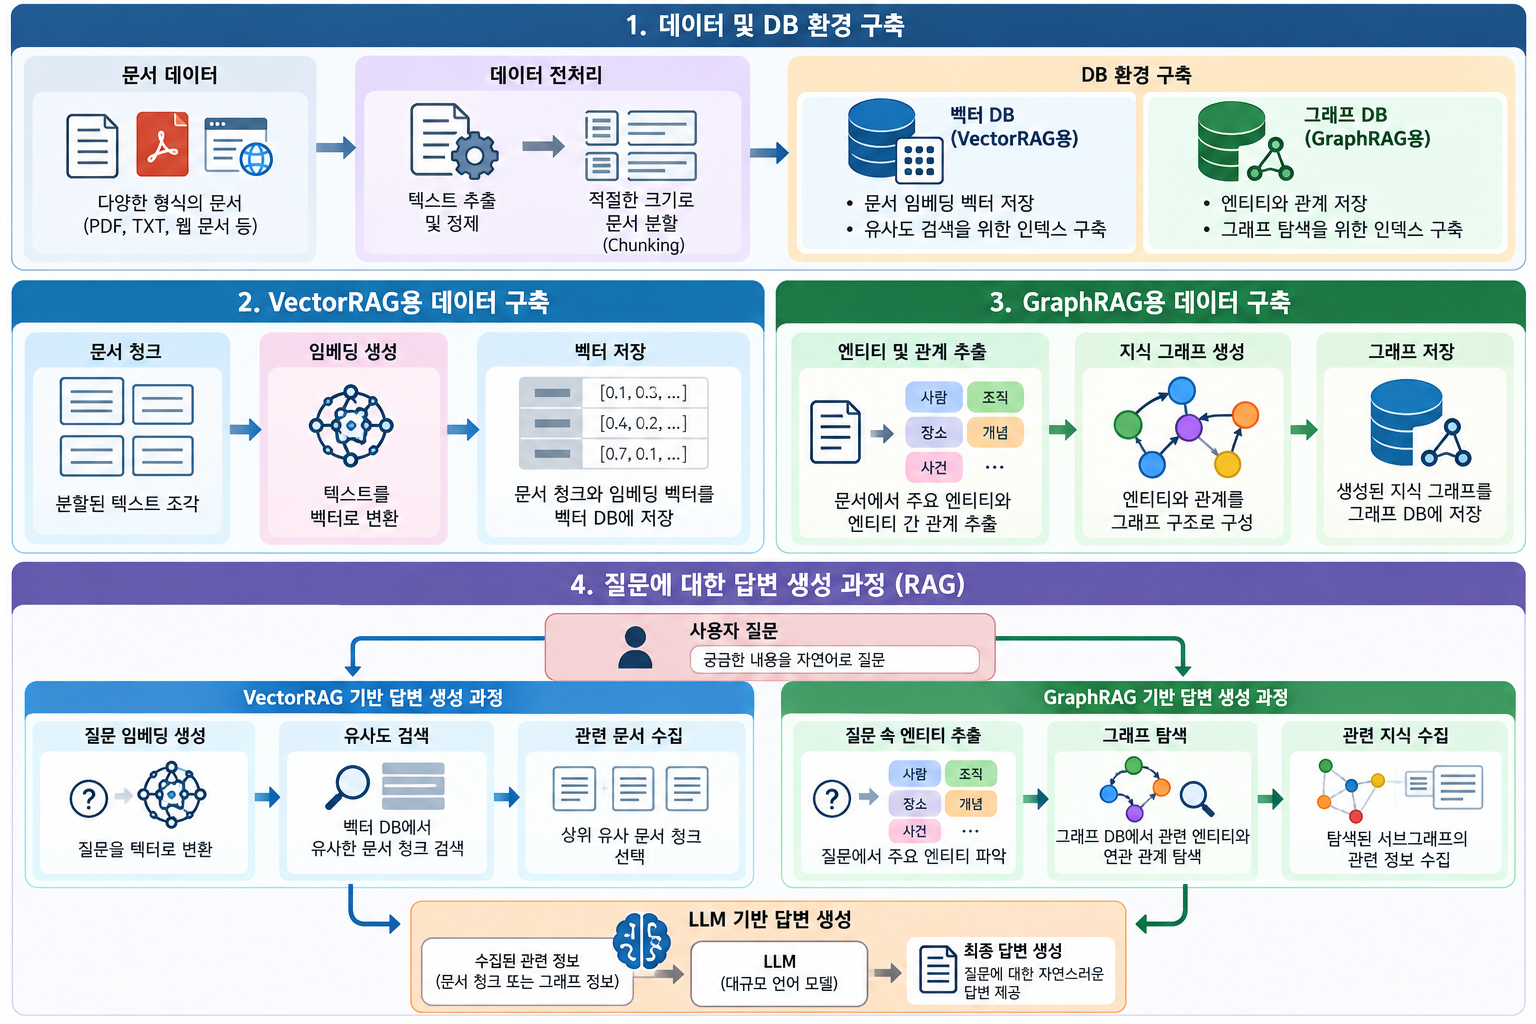

## 🔁 복습 질문

<details>
<summary>1. Excel 이슈는 코드로, Word 보고서는 LLM으로 카드를 만든 이유는?</summary>

Excel은 이미 칸이 나뉜 구조화 데이터라 코드가 정확하고 무료다. 자유 문장인 Word만 LLM이 필요하다.
</details>

<details>
<summary>2. 기술명 정규화를 하지 않으면?</summary>

`Kafka`·`kafka`·`카프카`가 다른 노드가 되어 같은 기술을 쓴 프로젝트가 연결되지 않는다.
</details>

<details>
<summary>3. 설계서에서 가짜 문제해결 카드가 나오는 것을 막으려면?</summary>

문서 유형별 허용 카드 유형 제한(설계서 → 적용기술), 사람 확인 엑셀에서 삭제 후 적재.
</details>

<details>
<summary>4. Gradio에서 탭마다 uuid로 thread_id를 만든 이유는?</summary>

사용자마다 대화 기억이 섞이지 않게 분리하기 위해서다.
</details>
